In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.signal import find_peaks, peak_widths, savgol_filter
from scipy.optimize import curve_fit
import pandas as pd
import h5py
from typing import Literal
import struct
from uncertainties import ufloat

plt.rcParams["figure.dpi"] = 100

cmap = plt.colormaps["viridis"]

In [2]:
def plot_with_peaks(
    data,
    n_bins,
    divide=1.0,
    prominence=None,
    xlabel="",
    ylabel="Count",
    title="",
    xlims=None,
    savgol_window=None,
    savgol_strength=1.0,
    clip_counts=None,
    stacked=False,
    legend=None,
    bin_range=None,
    text_size=5,
    label=None,
    scatter=False,
    offset_annotations_right=0.0,
    offset_annotations_up=None,
    color=None,
    fmt="--o",
    no_ebars=False,
    rng_annotations_up=0.0,  # what a terrible way to do this :/
    show_uncert=True,
    weights=None,  # V4: per-record weights (a list of them when stacked)
    batch_weights=None,  # V4: [records][32 batches] weights -> batch MC errors
):
    if not stacked:
        signals = [data]
    else:
        signals = data

    weight_list = weights if (stacked and weights is not None) else [weights] * len(signals)
    bottom = np.zeros(n_bins)

    for signal, w in zip(signals, weight_list):
        counts, bins = np.histogram(signal, bins=n_bins, density=False, range=bin_range, weights=w)
        counts = np.array(counts)
        if batch_weights is not None:  # V4: errors from the scatter of the 32 shower batches
            per_batch = np.array([np.histogram(signal, bins=bins, weights=bw)[0] for bw in batch_weights.T])
            uncerts = np.sqrt(batch_weights.shape[1] * per_batch.var(0, ddof=1)) / divide
        else:
            uncerts = np.sqrt(counts) / divide
        counts = counts / divide

        if savgol_window is not None:
            background = savgol_filter(counts, window_length=savgol_window, polyorder=3)
            counts = counts - background * savgol_strength

        if clip_counts is not None:
            counts[counts > clip_counts] = clip_counts

        bin_width = np.diff(bins).mean()
        bin_centers = (bins[:-1] + bins[1:]) / 2.0
        height_scale = counts.max()

        if scatter:
            plt.errorbar(
                bin_centers,
                counts,
                label=label,
                yerr=uncerts,
                fmt=fmt,
                markersize=4,
                capsize=0 if no_ebars else 3,
                elinewidth=0 if no_ebars else 1,
                c=color,
                linewidth=1,
                # ecolor="k",
                # mfc="white",
                # mec=color
            )
        else:
            plt.bar(
                bin_centers,
                counts,
                width=bin_width,
                align="center",
                bottom=bottom,
                label=label,
                color=color,
            )

        plt.xlim(xlims)
        bottom += counts
        bottom = np.round(bottom, 10)
        if prominence is not None:
            peaks, props = find_peaks(counts, prominence=prominence)
            half_widths = peak_widths(counts, peaks)[0] * bin_width
            for x, y, half_width in zip(bin_centers[peaks], counts[peaks], half_widths):
                plt.errorbar(
                    [x],
                    [y],
                    xerr=[half_width],
                    c="black",
                    fmt="",
                    capsize=2,
                    elinewidth=0.2,
                    capthick=0.2,
                )
                plt.annotate(
                    f"{x:.04f} ± {half_width:.04f} MeV" if show_uncert else f"{x:.03f} MeV",
                    (
                        x + offset_annotations_right,
                        (
                            y
                            + (
                                (height_scale * (0.01 * text_size))
                                if offset_annotations_up is None
                                else offset_annotations_up
                            ) + (np.random.random() - 0.5) * rng_annotations_up
                        ),
                    ),
                    ha="left",
                    fontsize=text_size,
                )

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    # plt.ylim(ylims)
    plt.title(title)
    if legend is not None:
        plt.legend(legend)

    # plt.show()

In [3]:
# thx chatgpt


def fwhm(E):
    return np.sqrt(
        (5e-4) ** 2 + 0.000004 * E  # electronics noise  # statistical broadening
    )


# Convert FWHM -> sigma
def sigma(E):
    return fwhm(E) / 2.355

# Loaders

In [4]:
keys = [
    "Edep",
    "sourceE",
    "sourcePDG",
    "zInSoil",
    "rhoInSoil",
    # "sourceE"
]


def decode(b):
    return b.decode("utf-8")


decode_v = np.vectorize(decode)


def load_hdf5(path):
    dfs = []
    with h5py.File(path, "r") as f:
        for key in keys:
            data = f["default_ntuples"]["Measurement"][key]["pages"][()]
            if isinstance(data[0], bytes):
                data = decode_v(data)

            dfs.append(pd.DataFrame(data, columns=[key]))

    return pd.concat(dfs, axis=1)


def load_csv(path):
    df = pd.read_csv(path, comment="#", header=None)
    df.columns = keys.copy()
    print(f"{df.shape[0]:,} interactions recorded")
    return df


def load_raw(path):
    rows = []
    with open(path, "rb") as file:
        while data := file.read(3 * 8):
            energy, p_z, depth = struct.unpack("ddd", data)
            rows.append([energy, p_z, depth])
    df = pd.DataFrame(rows, columns=["E", "p_z", "z"])
    return df

In [5]:
# V4 loader. V4 does not record detector pulses one by one: the transport stage fills
# histograms of energy deposited (1 keV bins, 0-12 MeV) split into 32 batches of whole cosmic
# showers, and by the origin class of the gamma (process x target nucleus). load_v4_detection()
# turns a run into pseudo-records with load_csv's "Edep" column:
#   Edep: bin centre (MeV); w: expected counts per day; b0..b31: the same per shower batch.
# MC errors come from the batch scatter (sigma = sqrt(32 var_b)), not sqrt(N), because one shower
# gives several correlated hits. Spectra are ideal resolution, cleaned of single heavy-weight hits
# and capture-corrected with v4lib (Final Data/v4_final/v4_analysis.ipynb, sections 2-3).
# Jay's "neutrons only" (source particle a neutron) is not in V4; the nearest equivalent is the
# hadronic origin classes (n capture + inelastic reactions, which include muon capture).
# Bin centres sit at x.5 keV, so energy windows below use whole-keV edges.
# Not in the V4 bundle: per-pulse source position (zInSoil, rhoInSoil) and source energy.

import sys
from pathlib import Path

PROJECT = Path.cwd().resolve().parents[2]  # .../ASC - Carbon Spec (run from ground-carbon/analysis)
sys.path.insert(0, str(Path.cwd() / "v4"))
sys.path.insert(0, str(PROJECT / "Final Data" / "v4_final"))
import v4lib as L  # V4 campaign helpers: capture correction, heavy-hit cleaning, NORM model, soil parameters
from spectra import CLASSES

# v4lib's built-in paths assume a different folder layout; point them at the data
L.RESULTS = PROJECT / "Final Data" / "v4_results_20261011" / "v4_results"
L.REDUCED = L.RESULTS / "reduced"
L.SOILS = PROJECT / "Geochemical Survey" / "Soil_Types_JSON_v2"
DAY = 86400.0

from spectra import Run, Resolution

BATCH_COLS = [f"b{k}" for k in range(L.N_BATCH)]
NEUTRON_CLASSES = [c for c in CLASSES if c.startswith(("capture", "inelastic"))]


def spectrum_frame(batches):
    """[32][12000] counts/s -> pseudo-records (Edep, w per day, b0..b31 per day)."""
    b = np.asarray(batches, float) * DAY
    f = pd.DataFrame(b.T, columns=BATCH_COLS)
    f.insert(0, "w", b.sum(0))
    f.insert(0, "Edep", L.E_MEV)
    return f


def class_batches(rid, classes):
    """CRY spectrum [32][12000] (counts/s) of some origin classes, capture-corrected (1 keV class
    shape; batch split from the 10 keV class x batch array, as spectra.Run.cry; not cleaned)."""
    run = Run.load(L.REDUCED, rid)
    f = L.class_factors(rid)
    return sum(run.cry([c]).batches * f[CLASSES.index(c)] for c in classes)


def load_v4_detection(rid):
    df = spectrum_frame(L.cry(rid))
    df.attrs["hadronic"] = spectrum_frame(class_batches(rid, NEUTRON_CLASSES))
    print(f"{df['w'].sum():,.0f} counts per day expected ({rid})")
    return df


def window_count(frame, e_low, e_high):
    """Counts per day with Edep in [e_low, e_high], and the batch MC sigma."""
    b = frame.loc[frame["Edep"].between(e_low, e_high), BATCH_COLS].sum(axis=0).to_numpy()
    return b.sum(), np.sqrt(L.N_BATCH * b.var(ddof=1))

In [6]:
# df15 = load_csv("finals/detection-15pc.csv")
# df10 = load_csv("finals/detection-10pc.csv")
# df5 = load_csv("finals/detection-5pc.csv")
# df1 = load_csv("finals/detection-1pc.csv")
#
# dfs = [df15, df10, df5, df1]
# pcs = np.array([0.15, 0.10, 0.05, 0.01])
# exposure_days = np.array([21.2131481481, 20.862037037, 20.462962963, 20.1990740741])
#
# neutrons = lambda df: df[df["sourcePDG"] == 2112]

# V4: one soil Order at five SOC levels (SOC x4, x2, central, x0.5, x0.25; everything else fixed)
ORDER = "chromosol"
soc_of = lambda rid: L.params(L.composition_id(rid))["soc"]  # dry-mass SOC (%), 0-30 cm
soc_runs = sorted((r for r in L.design_runs(ORDER, "soc", extended=True) if not r.endswith("_rep")),
                  key=lambda r: -soc_of(r))
dfs = [load_v4_detection(r) for r in soc_runs]
pcs = np.array([soc_of(r) / 100 for r in soc_runs])  # SOC mass fraction
exposure_days = np.ones(len(dfs))  # V4 spectra are already per day
norm_dfs = [spectrum_frame(L.norm_model(L.composition_id(r))) for r in soc_runs]  # V4: each soil's NORM
df15 = dfs[soc_runs.index(ORDER)]  # the central soil stands in for Jay's 15% run below

neutrons = lambda df: df.attrs["hadronic"]  # V4: hadronic origin classes
colour = lambda pc: cmap(0.9 * pc / pcs.max())  # V4: SOC fractions are ~0.1-4%, not 1-15%
print(dict(zip(soc_runs, (100 * pcs).round(2))))

368,786 counts per day expected (chromosol_soc_x4)
369,360 counts per day expected (chromosol_soc_x2)
374,733 counts per day expected (chromosol)
373,796 counts per day expected (chromosol_soc_x0.5)


374,624 counts per day expected (chromosol_soc_x0.25)


{'chromosol_soc_x4': np.float64(3.63), 'chromosol_soc_x2': np.float64(1.82), 'chromosol': np.float64(0.91), 'chromosol_soc_x0.5': np.float64(0.45), 'chromosol_soc_x0.25': np.float64(0.23)}


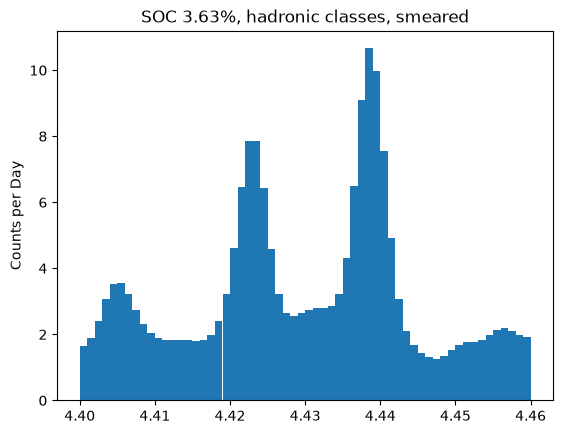

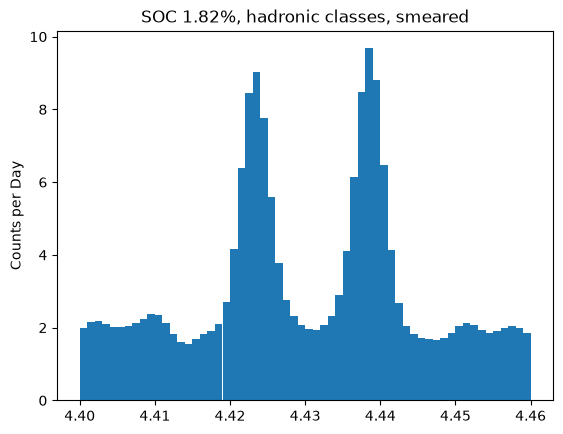

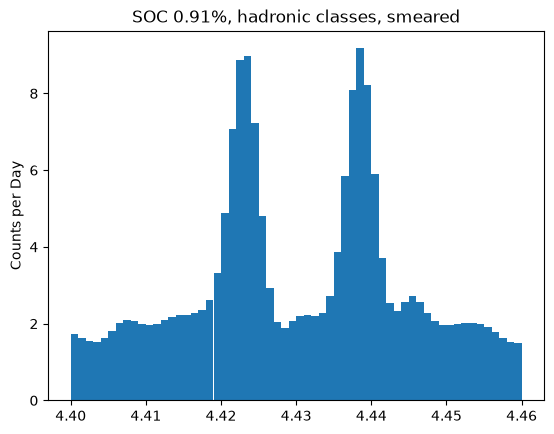

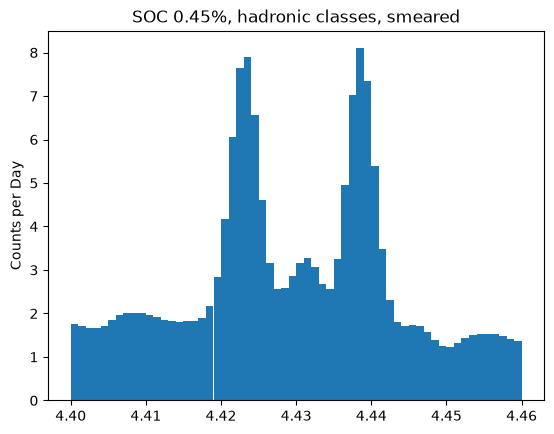

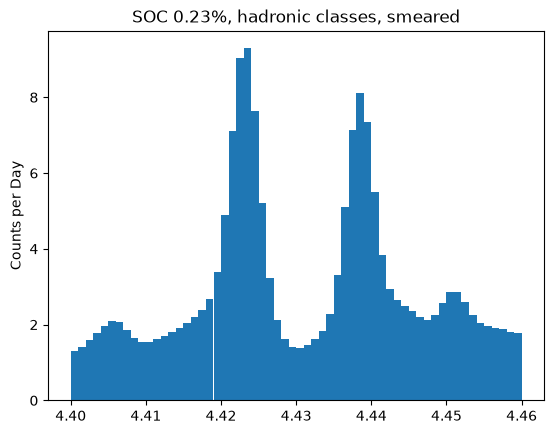

In [7]:
# V4: smear the histogram with Jay's resolution (fwhm() above, in keV: sqrt(0.25 + 0.004 E[keV]))
jay_res = Resolution(0.25, 0.004, 0.0, "Jay")

for pc, df in zip(pcs, [neutrons(df) for df in dfs]):
    smeared = spectrum_frame(jay_res.apply(df[BATCH_COLS].to_numpy().T) / DAY)
    range = smeared["Edep"].between(4.4, 4.46)
    plot_with_peaks(smeared[range]["Edep"], 60, weights=smeared[range]["w"], bin_range=(4.4, 4.46),
                    title=f"SOC {pc:.2%}, hadronic classes, smeared", ylabel="Counts per Day")
    plt.show()

# Analysis

## Masking Utilities

## Energy Spectrum

4.438 MeV
  $91 \pm 106$ & 0.20
  z=0.8560976037131055
  sens=$6.333 \pm 7.397$
  sens with NORM=$6.333 \pm 7.397$ (NORM 0/day)
None
  $70 \pm 92$ & 0.28
  z=0.7616237710266354
  sens=$8.098 \pm 10.633$
4.439 MeV
  $233 \pm 56$ & 0.63
  z=4.149895157769056
  sens=$1.471 \pm 0.355$
  sens with NORM=$1.471 \pm 0.355$ (NORM 0/day)
None
  $245 \pm 34$ & 0.86
  z=7.12486318159242
  sens=$1.379 \pm 0.194$
4.438 & 4.439 MeV
  $318 \pm 127$ & 0.18
  z=2.505065356867931
  sens=$2.098 \pm 0.838$
  sens with NORM=$2.098 \pm 0.838$ (NORM 0/day)
None
  $318 \pm 111$ & 0.20
  z=2.8531251728063856
  sens=$2.076 \pm 0.727$
4.423 MeV
  $-15 \pm 143$ & 1.18
  z=-0.10289026005276383
  sens=$-43.282 \pm 420.666$
  sens with NORM=$-43.282 \pm 420.666$ (NORM 0/day)
None
  $-124 \pm 97$ & 1.08
  z=-1.2725063863935613
  sens=$-5.075 \pm 3.989$
4.406 MeV
  $4 \pm 109$ & 2.86
  z=0.038161147483104244
  sens=$110.175 \pm 2887.095$
  sens with NORM=$110.175 \pm 2887.095$ (NORM 0/day)
None
  $35 \pm 72$ & 1.68
  z

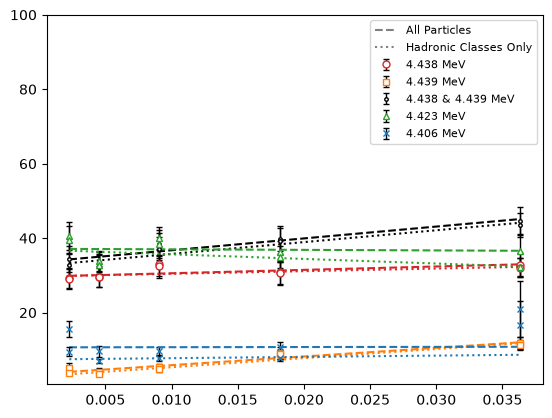

All Particles


  $-19203 \pm 7619$ & 0.37
  z=-2.5204443097089073
  sens=$-0.832 \pm 0.330$
  sens with NORM=$-3.365 \pm 1.335$ (NORM 392058/day)
Hadronic Classes Only
  $-1542 \pm 3449$ & 0.94
  z=-0.4470159827239836
  sens=$-1.679 \pm 3.756$


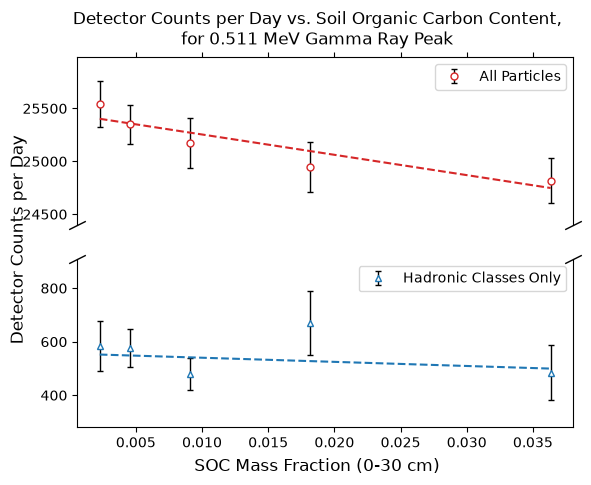

In [8]:
def quadratic_model(x, a, b, c):
    return a * np.pow(x, 2) + b * x + c


def linear_model(x, m, c):
    return m * x + c


def analyse_peak_trend(
    e_low,
    e_high,
    label,
    mapper=lambda _: _,
    color=None,
    fmt=".",
    trendline="--",
    model=None,
    ax=None,
):

    ax = plt.gca() if ax is None else ax

    model = linear_model if model is None else model
    print(label)

    counts_per_day, uncert = [], []
    for df in dfs:
        n, s = window_count(mapper(df), e_low, e_high)  # V4: batch MC errors
        counts_per_day.append(n)
        uncert.append(s)
    counts_per_day, uncert = np.array(counts_per_day), np.array(uncert)

    # uncert = [np.sqrt(n) for n in counts_per_day]
    counts_per_day /= exposure_days
    uncert /= exposure_days

    ax.errorbar(
        pcs,
        counts_per_day,
        yerr=uncert,
        fmt=fmt,
        label=label,
        c=color,
        elinewidth=1,
        capsize=2,
        markersize=5,
        mfc="white",
        ecolor="k",
    )
    # ax.set_title(f"Detector Counts per Day vs. Soil Organic Carbon Content")
    # ax.set_xlabel("Soil Organic Carbon Volume Fraction")
    # ax.set_ylabel("Detector Counts per Day")

    opt, cov = curve_fit(
        model,
        pcs,
        counts_per_day,
        sigma=uncert,
        absolute_sigma=True,
    )
    # gradient, gradient_u = opt[0], np.sqrt(cov[0, 0])
    x = np.linspace(pcs.min(), pcs.max(), 64)
    ax.plot(x, model(x, *opt), trendline, c=color)

    resids = counts_per_day - model(pcs, *opt)
    chi_squared = np.sum((resids / uncert) ** 2)
    dof = len(pcs) - len(opt)
    reduced_chi_squared = chi_squared / dof
    # print(f"  {reduced_chi_squared=:.2f}")
    # for i, param in enumerate(opt):
    # print(f"  opt[{i}]: {param:.0f} +/- {np.sqrt(cov[i, i]):.0f}")

    m = opt[0]
    m_u = np.sqrt(cov[0, 0])
    b = opt[1]
    b_u = np.sqrt(cov[1, 1])
    uncert_1day = np.sqrt(max(counts_per_day))
    sens = 100 * uncert_1day / ufloat(m, m_u)
    print(f"  ${m:.0f} \\pm {m_u:.0f}$ & {reduced_chi_squared:.2f}")
    print(f"  z={m/m_u}")
    print(f"  sens=${sens.n:.3f} \\pm {sens.s:.3f}$")
    if mapper is not neutrons:  # V4: the soil's own NORM counts in the same window add noise
        norm_1day = max(window_count(n, e_low, e_high)[0] for n in norm_dfs)
        sens_norm = 100 * np.sqrt(max(counts_per_day) + norm_1day) / ufloat(m, m_u)
        print(f"  sens with NORM=${sens_norm.n:.3f} \\pm {sens_norm.s:.3f}$ (NORM {norm_1day:.0f}/day)")
    return counts_per_day, uncert  # V4: for the axis limits below


# V4: windows on whole-keV edges. The 4.438 bin is the line made on oxygen (16O(n,n'a)12C*),
# the 4.439 bin the line from carbon itself (see "V4: origin classes" below).
analyse_peak_trend(4.438, 4.439, "4.438 MeV", color="tab:red", fmt="o")
analyse_peak_trend(
    4.438,
    4.439,
    None,
    color="tab:red",
    fmt="o",
    mapper=neutrons,
    trendline=":",
)

analyse_peak_trend(4.439, 4.440, "4.439 MeV", color="tab:orange", fmt="s")
analyse_peak_trend(
    4.439,
    4.440,
    None,
    color="tab:orange",
    fmt="s",
    mapper=neutrons,
    trendline=":",
)

analyse_peak_trend(4.438, 4.440, "4.438 & 4.439 MeV", color="k", fmt=".")
analyse_peak_trend(
    4.438,
    4.440,
    None,
    color="k",
    fmt=".",
    mapper=neutrons,
    trendline=":",
)

analyse_peak_trend(4.422, 4.424, "4.423 MeV", color="tab:green", fmt="^")
analyse_peak_trend(
    4.422,
    4.424,
    None,
    color="tab:green",
    fmt="^",
    mapper=neutrons,
    trendline=":",
)

analyse_peak_trend(4.404, 4.408, "4.406 MeV", color="tab:blue", fmt="x")
analyse_peak_trend(
    4.404,
    4.408,
    None,
    color="tab:blue",
    fmt="x",
    mapper=neutrons,
    trendline=":",
)
# analyse_peak_trend(4.933, 4.935, "4.934 MeV", color="tab:blue", fmt="^")

# analyse_peak_trend(
#     4.933,
#     4.935,
#     None,
#     color="tab:blue",
#     fmt="^",
#     mapper=neutrons,
#     trendline="-.",
# )
plt.plot([], [], "--", label="All Particles", color="gray")
plt.plot([], [], ":", label="Hadronic Classes Only", color="gray")

# analyse_peak_trend(6.128, 6.130)
# analyse_peak_trend(1.367, 1.369)
# analyse_peak_trend(5, 10)
plt.ylim(top=100)
plt.legend(fontsize=8)
# plt.yscale("log")
plt.show()

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)

c1, u1 = analyse_peak_trend(0.510, 0.512, "All Particles", color="tab:red", fmt="o", ax=ax1)
c2, u2 = analyse_peak_trend(
    0.510,
    0.512,
    "Hadronic Classes Only",
    color="tab:blue",
    fmt="^",
    mapper=neutrons,
    ax=ax2
)
# code taken from https://matplotlib.org/stable/gallery/subplots_axes_and_figures/broken_axis.html
ax1.set_ylim((c1 - 2 * u1).min(), (c1 + 2 * u1).max())  # V4: limits from the data
ax2.set_ylim((c2 - 2 * u2).min(), (c2 + 2 * u2).max())
ax1.spines.bottom.set_visible(False)
ax2.spines.top.set_visible(False)
ax1.xaxis.tick_top()
ax1.tick_params(labeltop=False)  # don't put tick labels at the top
ax2.xaxis.tick_bottom()

# ax1.errorbar([], [], fmt="o", c="tab:red", label="0.511 MeV (All)")
# ax1.errorbar([], [], fmt="^", c="tab:blue", label="0.511 MeV (Neutrons Only)")

d = .5  # proportion of vertical to horizontal extent of the slanted line
kwargs = dict(marker=[(-1, -d), (1, d)], markersize=12,
              linestyle="none", color='k', mec='k', mew=1, clip_on=False)
ax1.plot([0, 1], [0, 0], transform=ax1.transAxes, **kwargs)
ax2.plot([0, 1], [1, 1], transform=ax2.transAxes, **kwargs)

# analyse_peak_trend(1.778, 1.780, "1.779 MeV (All)")
# analyse_peak_trend(1.778, 1.780, "1.779 MeV (Neutrons)", mapper=neutrons)

# analyse_peak_trend(2.222, 2.224, "2.223 MeV (All)")
# analyse_peak_trend(2.222, 2.224, "2.223 MeV (Neutrons)", mapper=neutrons)

# analyse_peak_trend(7.134, 7.136, "7.135 MeV (All)")
# analyse_peak_trend(7.134, 7.136, "7.135 MeV (Neutrons)", mapper=neutrons)

# analyse_peak_trend(7.644, 7.646, "7.645 MeV (All)")
# analyse_peak_trend(7.644, 7.646, "7.645 MeV (Neutrons)", mapper=neutrons)


# analyse_peak_trend(0.05, 0.2, "Low energy (All)", fmt="x")
# analyse_peak_trend(3.538, 3.540, "3.539 MeV (All)", fmt="s")
# analyse_peak_trend(0.05, 0.2, "Low Energy (Neutrons)", fmt="x", mapper=neutrons)
# analyse_peak_trend(2.753, 2.755, "2.754 MeV (All)", fmt="s")
# analyse_peak_trend(3.538, 3.540, "3.539 MeV (Neutron)", fmt="s", mapper=neutrons)
# analyse_peak_trend(2.753, 2.755, "2.754 MeV (Neutron)", fmt="s", mapper=neutrons)

ax1.legend()
ax2.legend()
fig.supxlabel("SOC Mass Fraction (0-30 cm)")
fig.supylabel("Detector Counts per Day")
plt.suptitle(f"Detector Counts per Day vs. Soil Organic Carbon Content,\nfor 0.511 MeV Gamma Ray Peak")
plt.show()

In [9]:
PEAK_PROMINENCE = 5  # V4: counts per day per 1 keV bin (Jay's 150 was counts in his runs)

In [10]:
def get_peak_ratios(energies_a, energies_b, n_bins=100, prominence=100,
                    weights_a=None, weights_b=None, bin_range=None):  # V4: weighted histograms

    counts_a, bins_a = np.histogram(energies_a, bins=n_bins, density=False, weights=weights_a, range=bin_range)
    counts_b, bins_b = np.histogram(energies_b, bins=n_bins, density=False, weights=weights_b, range=bin_range)

    bin_centers_a = (bins_a[:-1] + bins_a[1:]) / 2.0
    bin_centers_b = (bins_b[:-1] + bins_b[1:]) / 2.0

    peaks_a, _ = find_peaks(counts_a, prominence=prominence)
    peaks_b, _ = find_peaks(counts_b, prominence=prominence)

    ratios = []
    for idx_a, e_a in enumerate(bin_centers_a[peaks_a]):
        if any(abs(e_a - e_b) < 0.01 for e_b in bin_centers_b[peaks_b]):
            idx_b = np.argmin([abs(e_a - e_b) for e_b in bin_centers_b[peaks_b]])
            ratio = counts_a[peaks_a][idx_a] / counts_b[peaks_b][idx_b]
            ratios.append(ratio)

    return np.array(ratios)


for df, pc in zip(dfs, pcs):
    mev_2_to_10 = df["Edep"].between(2.0, 10.0)
    hadronic = neutrons(df)  # V4: hadronic classes stand in for "source particle is a neutron"
    ratios = get_peak_ratios(
        df[mev_2_to_10]["Edep"],
        hadronic[mev_2_to_10]["Edep"],
        n_bins=8000,  # V4: 1 keV bins
        prominence=PEAK_PROMINENCE,
        weights_a=df[mev_2_to_10]["w"],
        weights_b=hadronic[mev_2_to_10]["w"],
        bin_range=(2.0, 10.0),
    )

    print(pd.DataFrame(ratios, columns=[str(pc)]).agg(["mean", "std", "sem", "count"]))

       0.036339508897849315
mean               1.226217
std                0.617111
sem                0.052532
count            138.000000
       0.018169754448924658
mean               1.239684
std                0.585977
sem                0.052203
count            126.000000
       0.009084877224462329
mean               1.259400
std                0.789664
sem                0.063427
count            155.000000
       0.004542438612231164
mean               1.220751
std                0.652850
sem                0.055176
count            140.000000
       0.002271219306115582
mean               1.366098
std                0.677848
sem                0.059451
count            130.000000


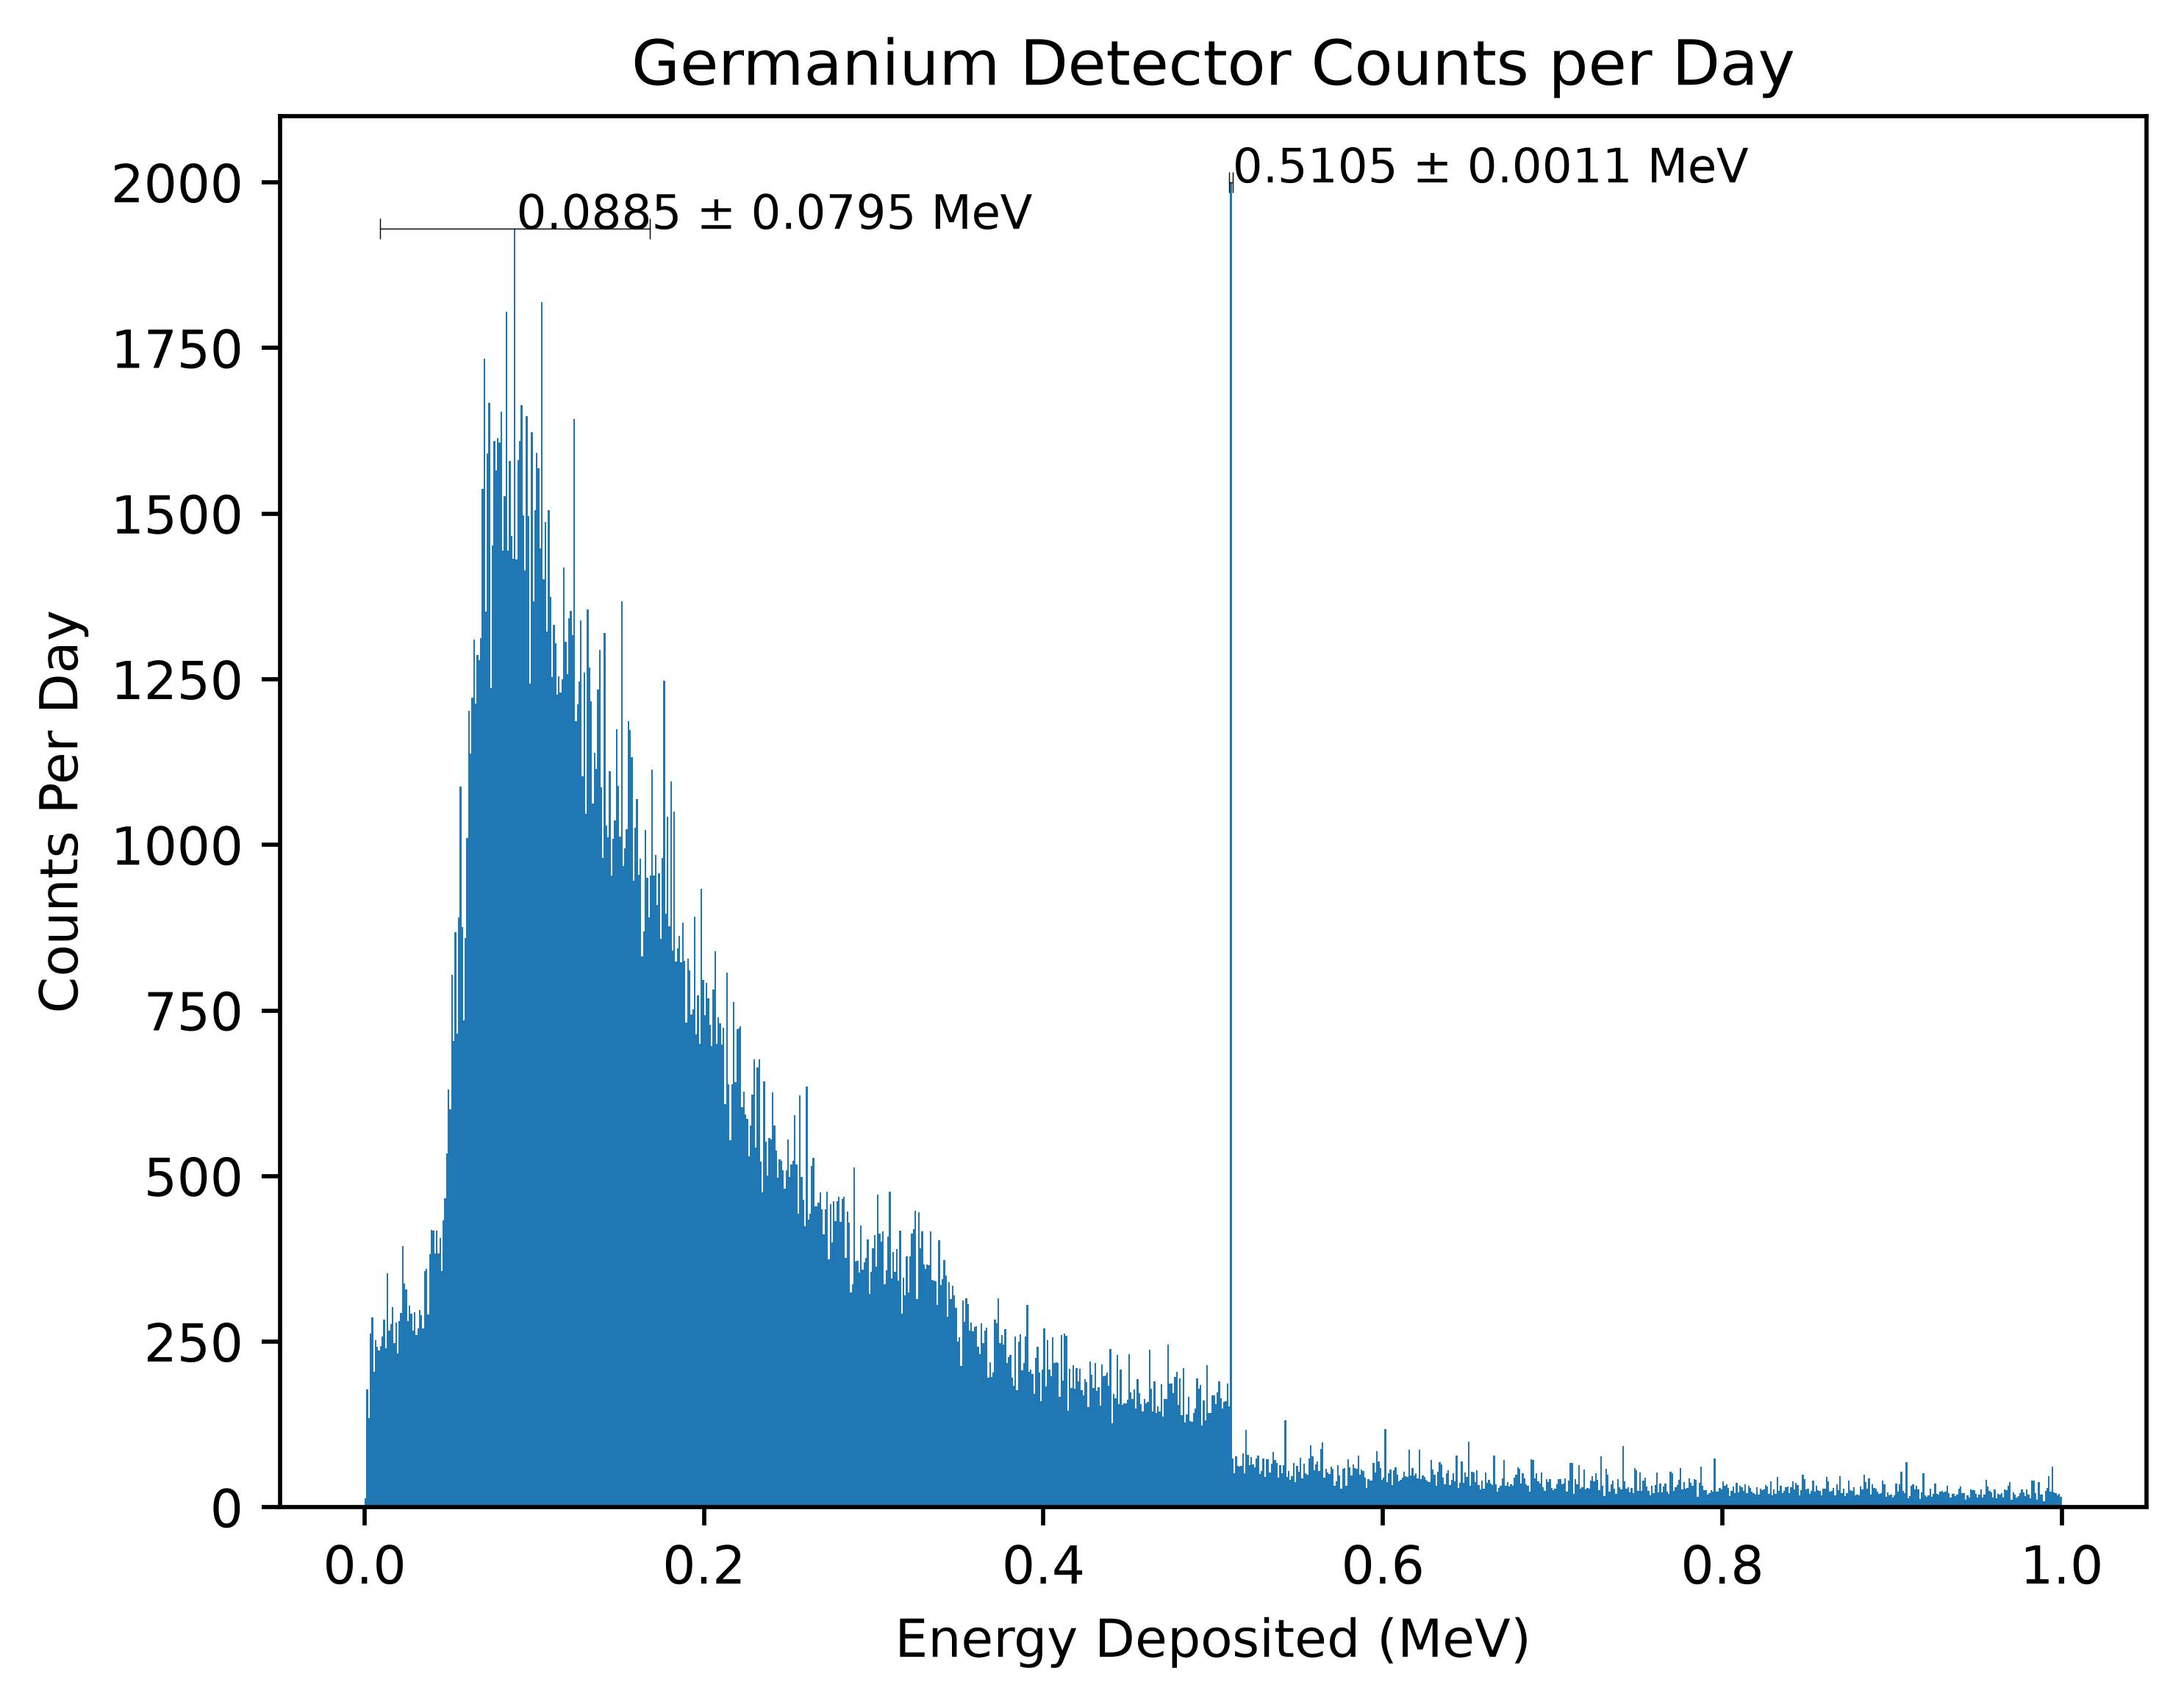

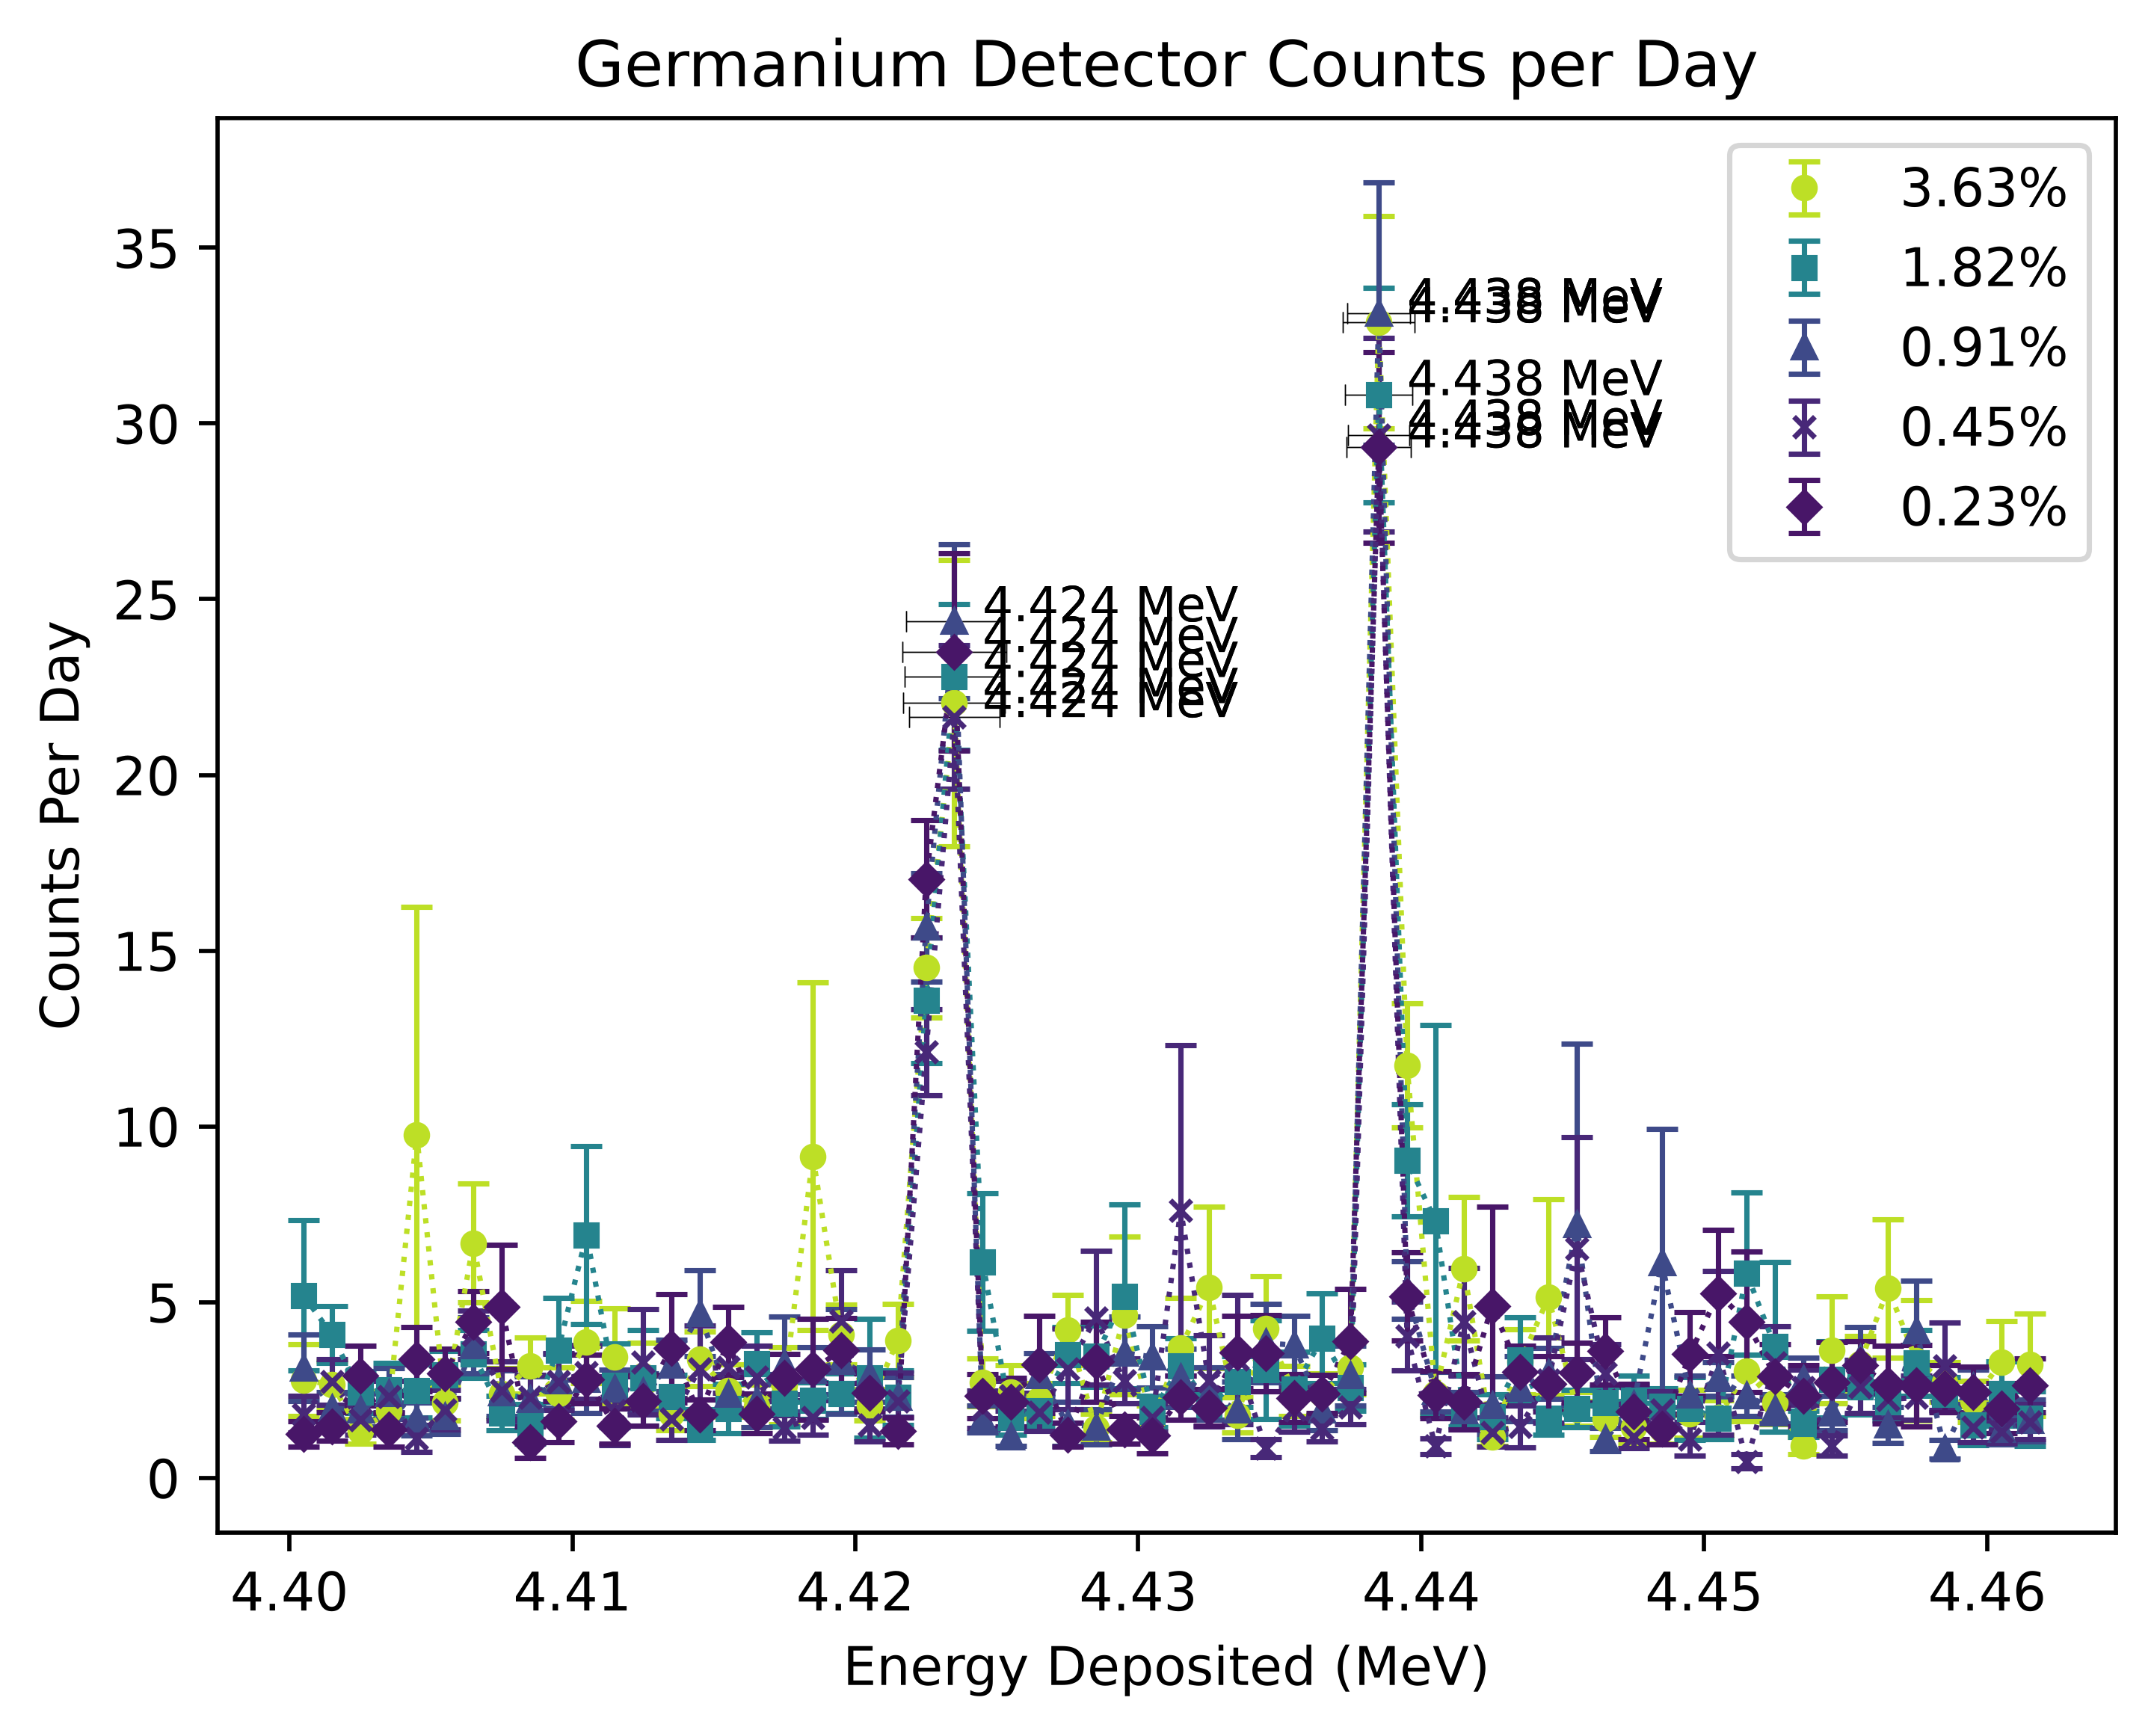

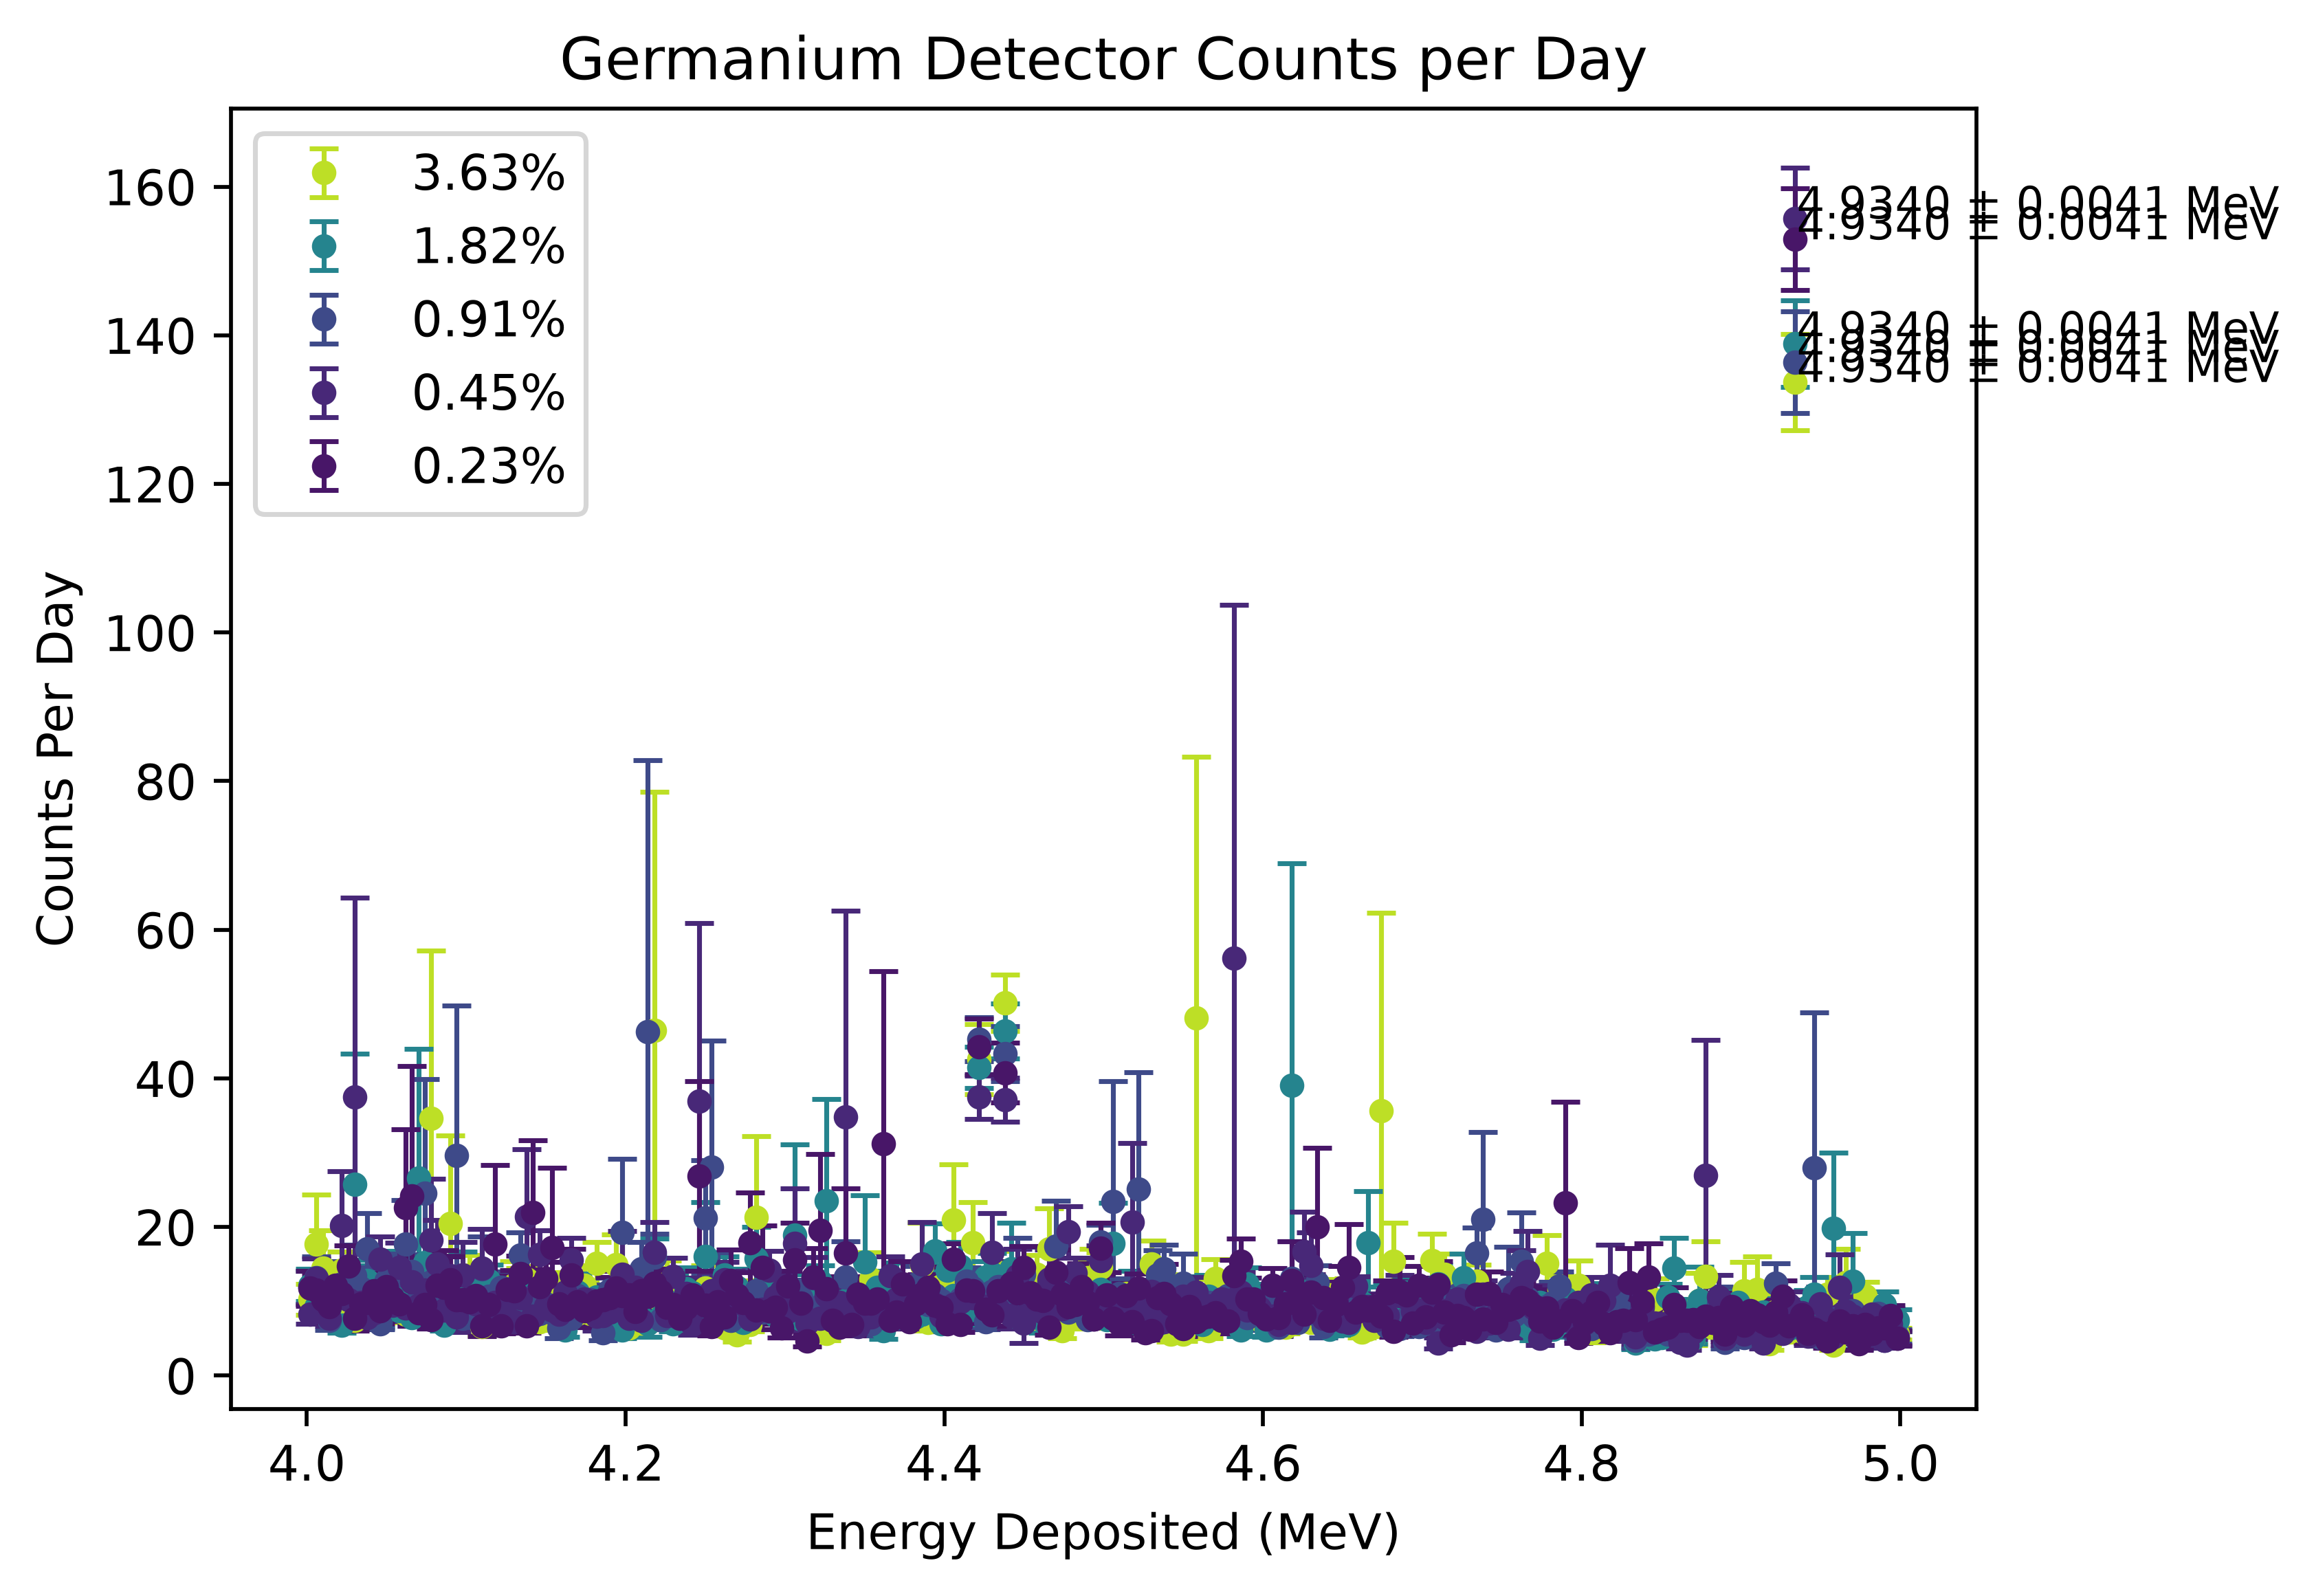

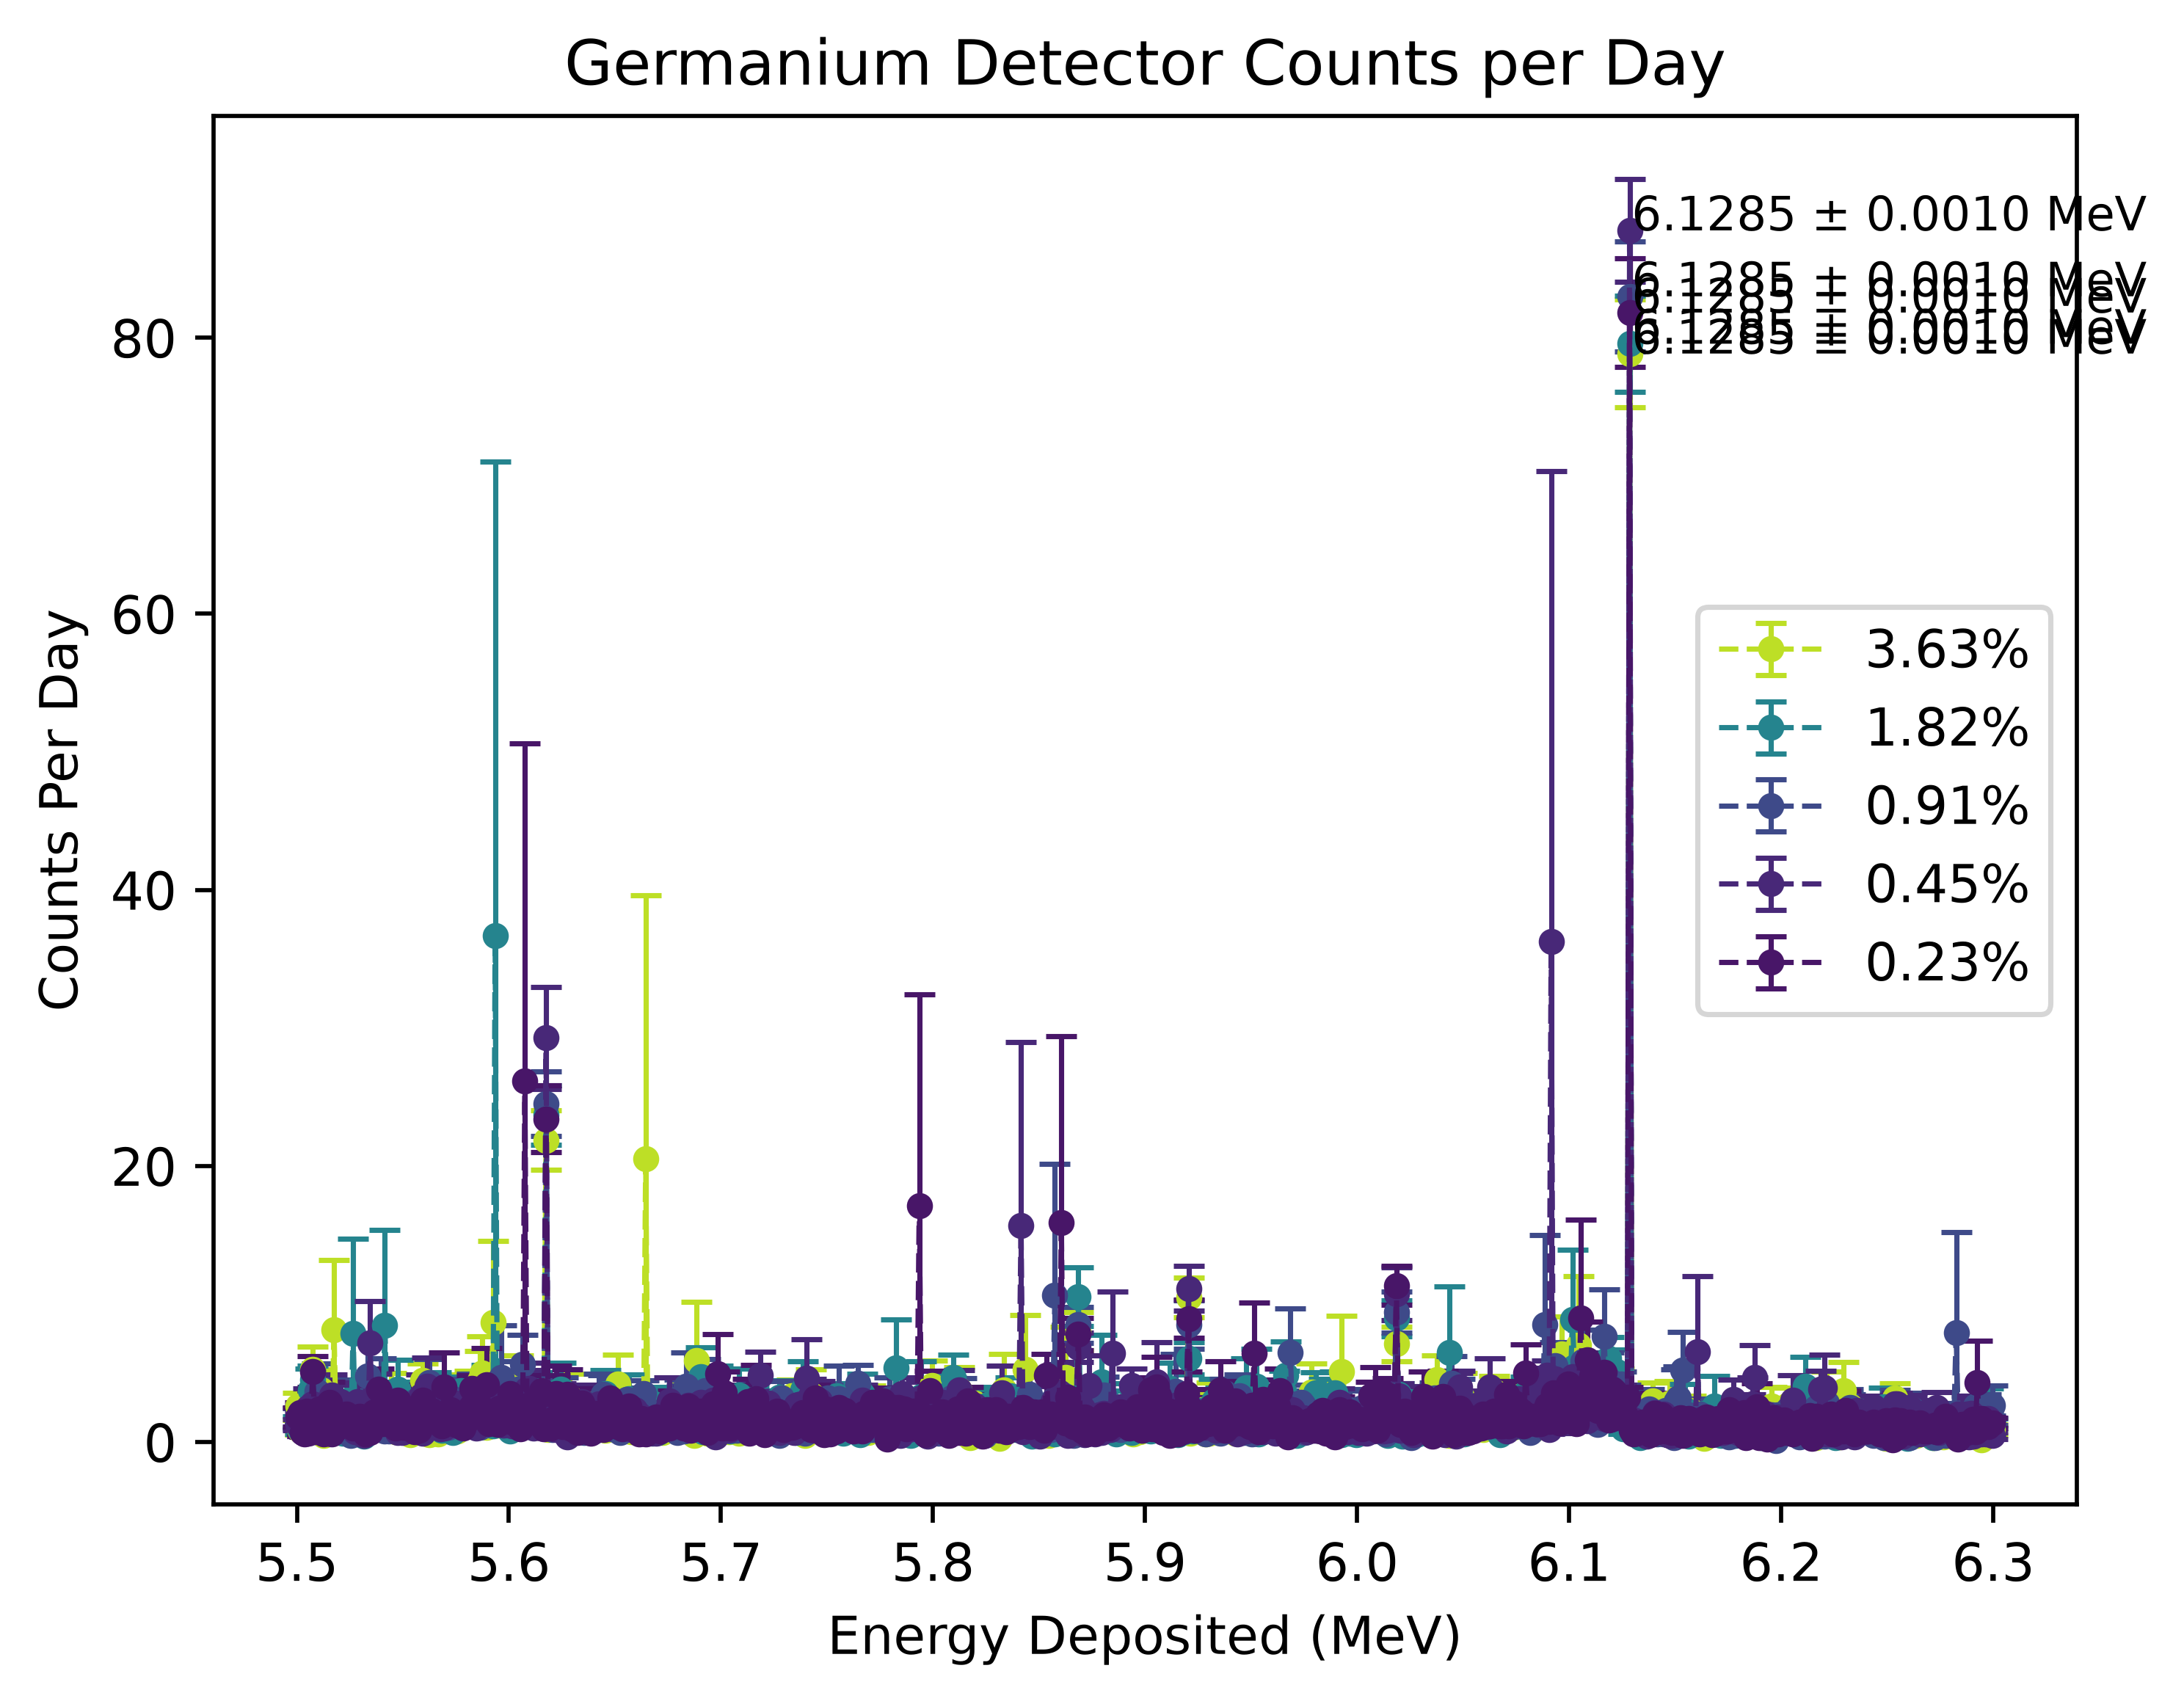

In [11]:
def plot_energy_spectrum(
    df,
    e_low,
    e_high,
    n_bins=512,
    prominence=None,
    clip=None,
    text_size=9,
    label=None,
    divide=1.0,
    color=None,
    scatter=True,
    fmt="o--",
    no_ebars=False,
    offset_annotations_up=0,
    offset_annotations_right=0.001,
    rng_annotations_up=0.0,
    show_uncert=True,
):
    sel = df[df["Edep"].between(e_low, e_high)]  # V4: weighted pseudo-records
    plot_with_peaks(
        data=sel["Edep"],
        weights=sel["w"],
        batch_weights=sel[BATCH_COLS].to_numpy(),
        bin_range=(e_low, e_high),
        n_bins=n_bins,
        prominence=prominence,
        xlabel="Energy Deposited (MeV)",
        title="Germanium Detector Counts per Day",
        clip_counts=clip,
        text_size=text_size,
        label=label,
        scatter=scatter,
        divide=divide,
        ylabel="Counts Per Day",  # V4 spectra are already per day
        offset_annotations_right=offset_annotations_right,
        offset_annotations_up=offset_annotations_up,
        color=color,
        fmt=fmt,
        no_ebars=no_ebars,
        rng_annotations_up=rng_annotations_up,
        show_uncert=show_uncert,
    )


plt.rcParams["figure.dpi"] = 512

# V4: bin counts changed so every bin holds whole 1 keV bins; prominences are in counts per day
plot_energy_spectrum(
    df15,
    0,
    1,
    n_bins=1000,
    prominence=1000,
    scatter=False,
    divide=exposure_days[0],
    clip=2000,
)

plt.show()
# plt.rcParams["figure.dpi"] = 100

for pc, df, exposure in zip(pcs, dfs, exposure_days):
    plot_energy_spectrum(
        df,
        4.4,
        4.462,
        n_bins=62,
        prominence=10,
        divide=exposure,
        color=colour(pc),
        fmt=":",
        no_ebars=True,
        show_uncert=False,
        offset_annotations_right=0.001
    )

for pc, df, exposure, fmt, prom in zip(
    pcs, dfs, exposure_days, ["o", "s", "^", "x", "D"], [10, 10, 10, 10, 10]
):
    plot_energy_spectrum(
        df,
        4.40,
        4.462,
        n_bins=62,
        prominence=prom,
        divide=exposure,
        label=f"{pc:.2%}",
        color=colour(pc),
        fmt=fmt,
        show_uncert=False,
        offset_annotations_right=0.001
    )

plt.legend()
plt.show()

for pc, df, exposure in zip(pcs, dfs, exposure_days):
    plot_energy_spectrum(
        df,
        4.0,
        5.0,
        n_bins=250,
        prominence=80,
        label=f"{pc:.2%}",
        divide=exposure,
        color=colour(pc),
        fmt="o",
    )
    # plot_energy_spectrum(df, 7.0, 7.2, n_bins=256, prominence=100, label=f"{pc}")
    # plot_energy_spectrum(df, 5.5, 6.3, n_bins=1024, prominence=100, divide=exposure, label=f"{pc}")

plt.legend()
plt.show()

for pc, df, exposure in zip(pcs, dfs, exposure_days):
    plot_energy_spectrum(
        df,
        5.5,
        6.3,
        n_bins=800,
        prominence=50,
        divide=exposure,
        label=f"{pc:.2%}",
        color=colour(pc),
    )
    # plot_energy_spectrum(df, 7.0, 7.2, n_bins=256, prominence=100, label=f"{pc}")

plt.legend()
plt.show()

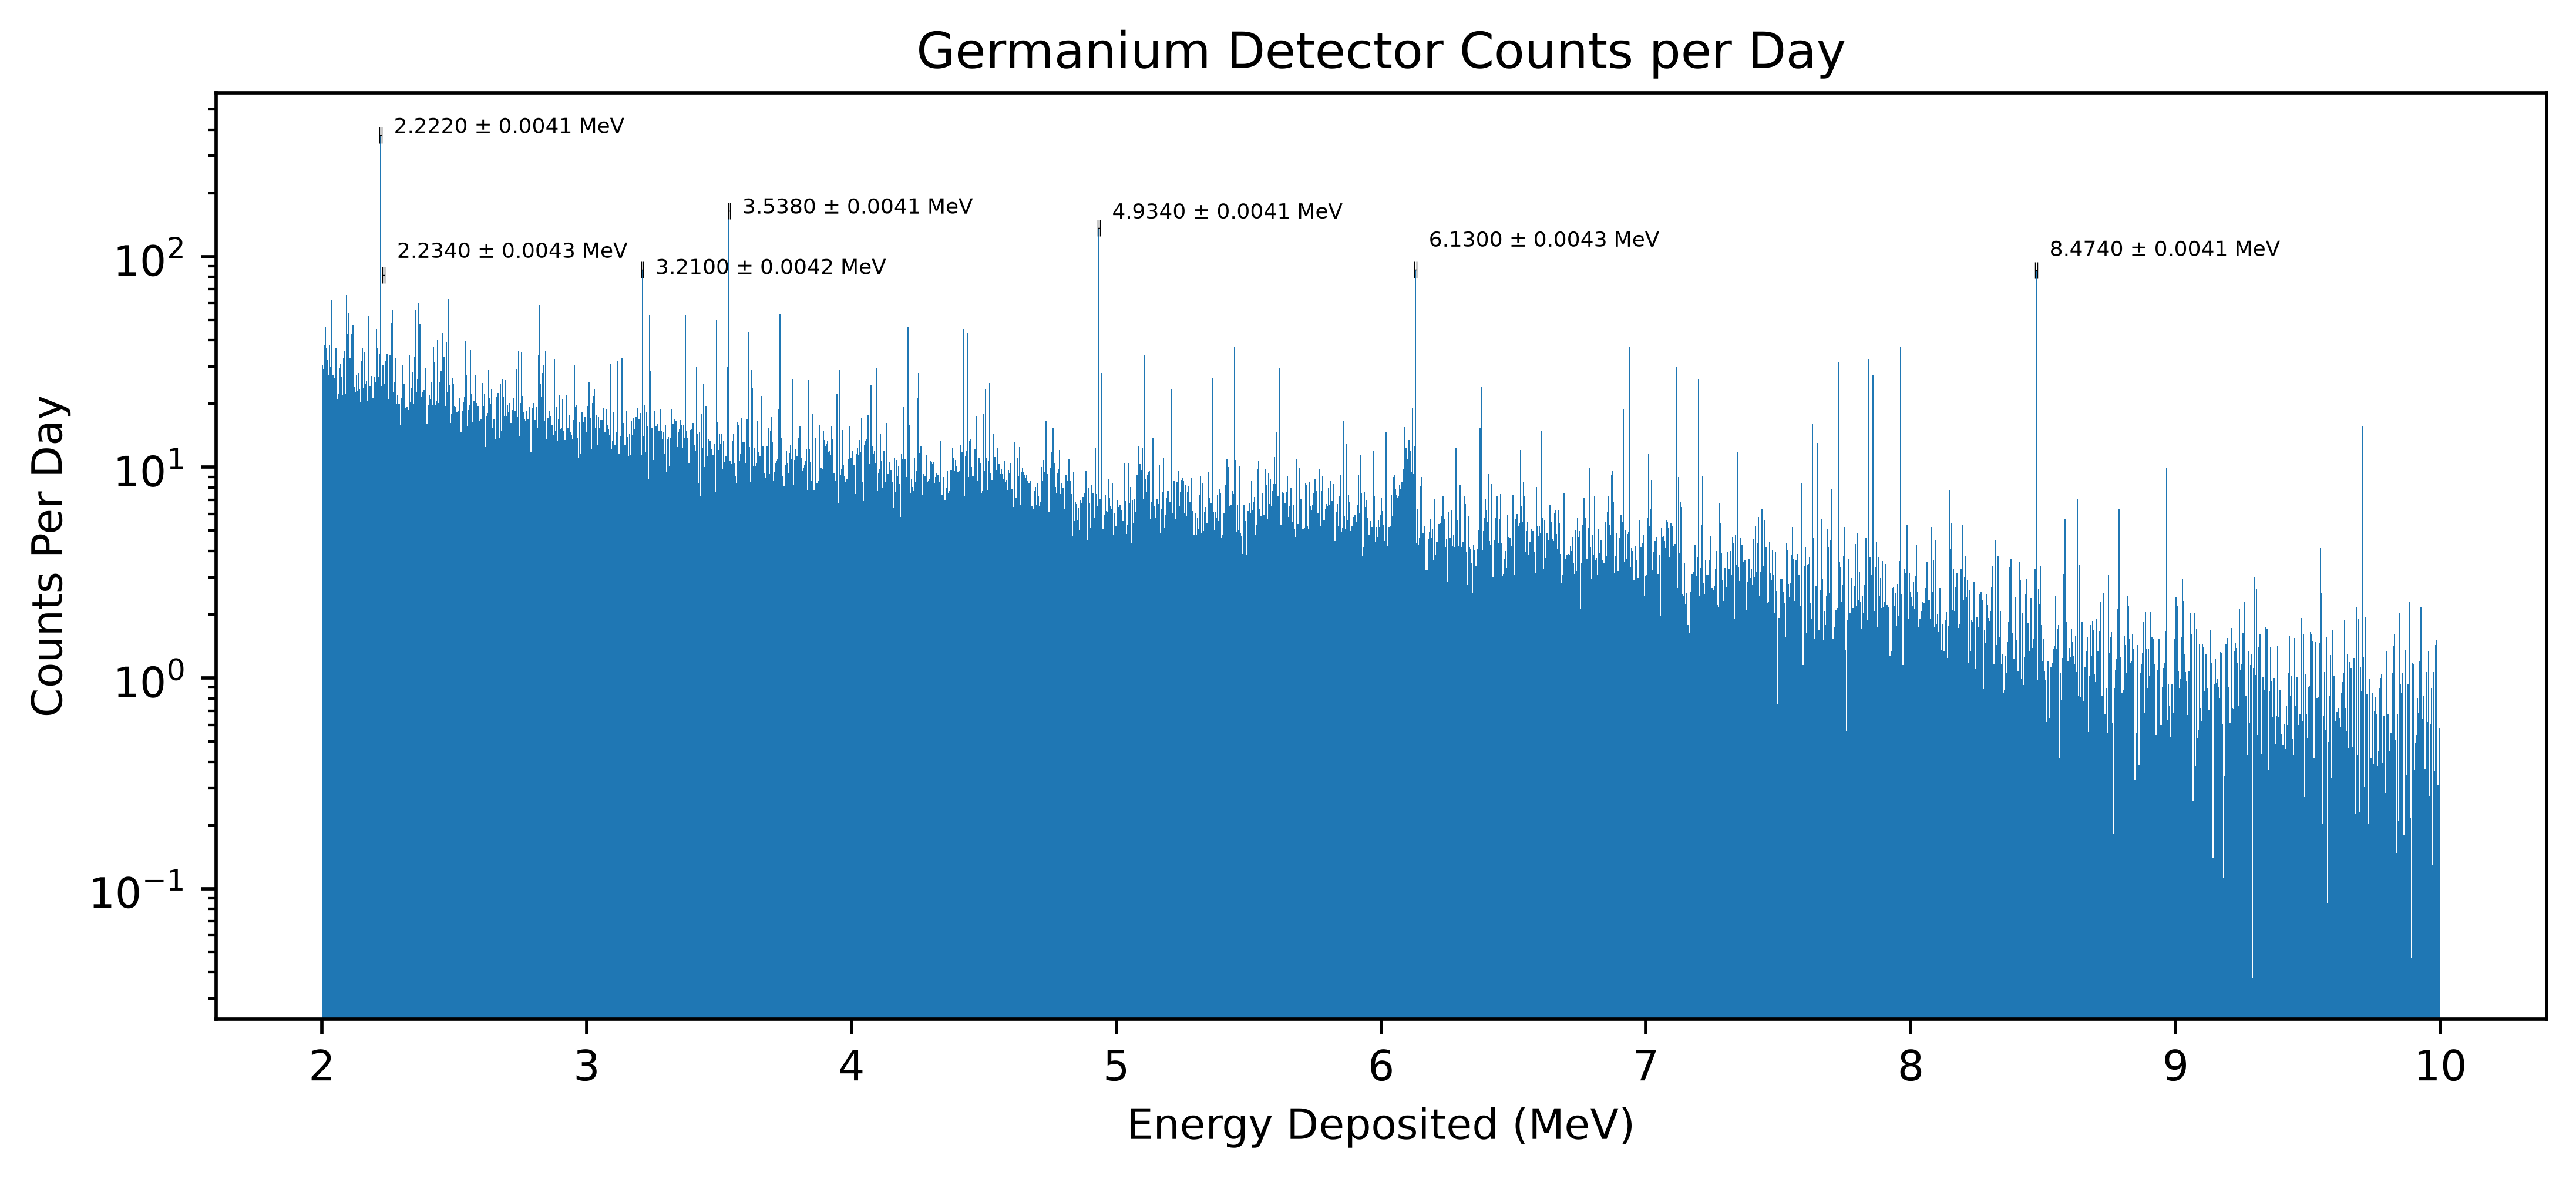

In [12]:
plt.figure(figsize=(10, 4))
plt.yscale("log")
plot_energy_spectrum(
    df15,
    2,
    10,
    n_bins=2000,  # V4: 4 keV bins
    prominence=50,
    scatter=False,
    divide=exposure_days[0],
    text_size=5,
    offset_annotations_up=0,
    offset_annotations_right=0.05,
    rng_annotations_up=50
)

plt.show()

In [13]:
# Not available for V4: per-pulse source position is not in the V4 bundle (depth of origin per line: analyse-transport, V4 section)
# # plt.figure(figsize=(5, 7))
#
# plt.title("Detection of Particles at Detector,\nby Position of Source in Soil")
#
# plt.hexbin(
#     df["rhoInSoil"] / 10,
#     df["zInSoil"] / 10,
#     # C=df["Edep"],
#     # reduce_C_function=np.mean,
#     linewidths=0.4,
#     # vmax=0.5,
#     # norm=LogNorm(),
# )
# plt.xlabel("Radius from Origin, $\\rho$ (cm)")
# plt.ylabel("Depth, $z$ (cm)")
# plt.colorbar(label="Count")
#
# plt.tight_layout()
# plt.show()

In [14]:
# Not available for V4: per-pulse source energy is not in the V4 bundle
# for i, (df, pc) in enumerate(zip(dfs, pcs)):
#     plt.title(f"Energy Deposited in Detector vs. Energy at Production\n({pc:.0%} Soil Carbon)")
#
#     mask = df["sourceE"].between(0.0, 5.0)
#     plt.hexbin(
#         df[mask]["sourceE"],
#         df[mask]["Edep"],
#         # C=df["Edep"],
#         # reduce_C_function=np.sum,
#         linewidths=0.5,
#         # vmax=100,
#         norm=LogNorm(),
#     )
#     plt.colorbar(label="Count")
#     plt.xlabel("Gamma Ray Energy at Production (MeV)")
#     plt.ylabel("Energy Deposited in Detector (MeV)")
#     plt.xlim(0.0, 5.0)
#     plt.ylim(0, 5.0)
#
#     plt.show()
#
# for i, (df, pc) in enumerate(zip([neutrons(df) for df in dfs], pcs)):
#     plt.title(f"Energy Deposited in Detector vs. Energy at Production\n({pc:.0%} Soil Carbon, Neutrons Only)")
#
#     mask = df["sourceE"].between(0.0, 5.0)
#     plt.hexbin(
#         df[mask]["sourceE"],
#         df[mask]["Edep"],
#         # C=df["Edep"],
#         # reduce_C_function=np.sum,
#         linewidths=0.5,
#         # vmax=100,
#         norm=LogNorm(),
#     )
#     plt.colorbar(label="Count")
#     plt.xlabel("Gamma Ray Energy at Production (MeV)")
#     plt.ylabel("Energy Deposited in Detector (MeV)")
#     plt.xlim(0.0, 5.0)
#     plt.ylim(0, 5.0)
#
#     plt.show()

# V4: new in this campaign

The cells above are Jay's analysis run on the V4 Chromosol SOC series. The sections below cover what
V4 added:

- what made each count (origin classes);
- the soil's own natural radioactivity (NORM);
- SOC sensitivity for all five soil Orders, with NORM and the direct cosmic background as noise;
- soil parameters that mimic SOC;
- a check that the batch errors are right;
- real NGSA sites;
- the analog runs (pulse timing and the direct cosmic background).

## V4: origin classes of the counts in each window

The class is that of the gamma born in the soil, so the Compton continuum of an oxygen-made gamma
counts as `inelastic_O`. Ideal resolution, central Chromosol, capture-corrected.

In [15]:
run = Run.load(L.REDUCED, ORDER)
tc = run.data["t_class"].astype(float) * run.cry_scale * L.class_factors(ORDER)[:, None] * DAY  # [class][1 keV]
windows = {"0.511 MeV (510-512 keV)": (510, 512), "2.223 MeV (2223)": (2223, 2224),
           "4.438 MeV bin (4438)": (4438, 4439), "4.439 MeV bin (4439)": (4439, 4440),
           "4.40-4.48 MeV": (4400, 4480), "6.129 MeV ±3 keV": (6126, 6132), "3-8 MeV continuum": (3000, 8000)}
shares = pd.DataFrame({w: tc[:, lo:hi].sum(1) for w, (lo, hi) in windows.items()}, index=CLASSES)
display((shares.div(shares.sum(axis=0), axis=1) * 100).round(1).loc[lambda t: t.max(axis=1) >= 0.5].rename_axis("% of counts"))
shares.sum(axis=0).round(1).rename("counts per day").to_frame().T

,0.511 MeV (510-512 keV),2.223 MeV (2223),4.438 MeV bin (4438),4.439 MeV bin (4439),4.40-4.48 MeV,6.129 MeV ±3 keV,3-8 MeV continuum
% of counts,,,,,,,
em_other,98.1,1.1,1.6,9.6,42.7,1.3,29.7
capture_H,0.1,98.5,0.0,0.0,0.0,0.0,0.0
capture_Si,0.3,0.0,0.0,13.6,16.6,1.4,11.1
capture_Fe,0.1,0.0,0.0,0.0,0.9,0.4,2.2
capture_other,0.2,0.0,0.7,0.0,3.6,0.3,6.6
inelastic_C,0.0,0.0,9.6,56.5,2.2,0.0,0.5
inelastic_O,0.6,0.2,87.1,14.6,22.3,76.8,28.7
inelastic_Si,0.5,0.1,1.1,5.7,9.3,2.3,16.2
inelastic_Fe,0.0,0.0,0.0,0.0,0.4,0.0,0.6


,0.511 MeV (510-512 keV),2.223 MeV (2223),4.438 MeV bin (4438),4.439 MeV bin (4439),4.40-4.48 MeV,6.129 MeV ±3 keV,3-8 MeV continuum
counts per day,25161.6,352.5,33.0,5.2,407.0,92.6,11360.0


## V4: NORM background

Each soil gets a NORM spectrum (K-40, U-238 and Th-232 chains in secular equilibrium), simulated per
Bq/kg and scaled by the soil's measured activities and its mineral fraction. NORM templates are pooled
over each Order's runs (v4lib) to cut their MC noise. HPGe resolution.

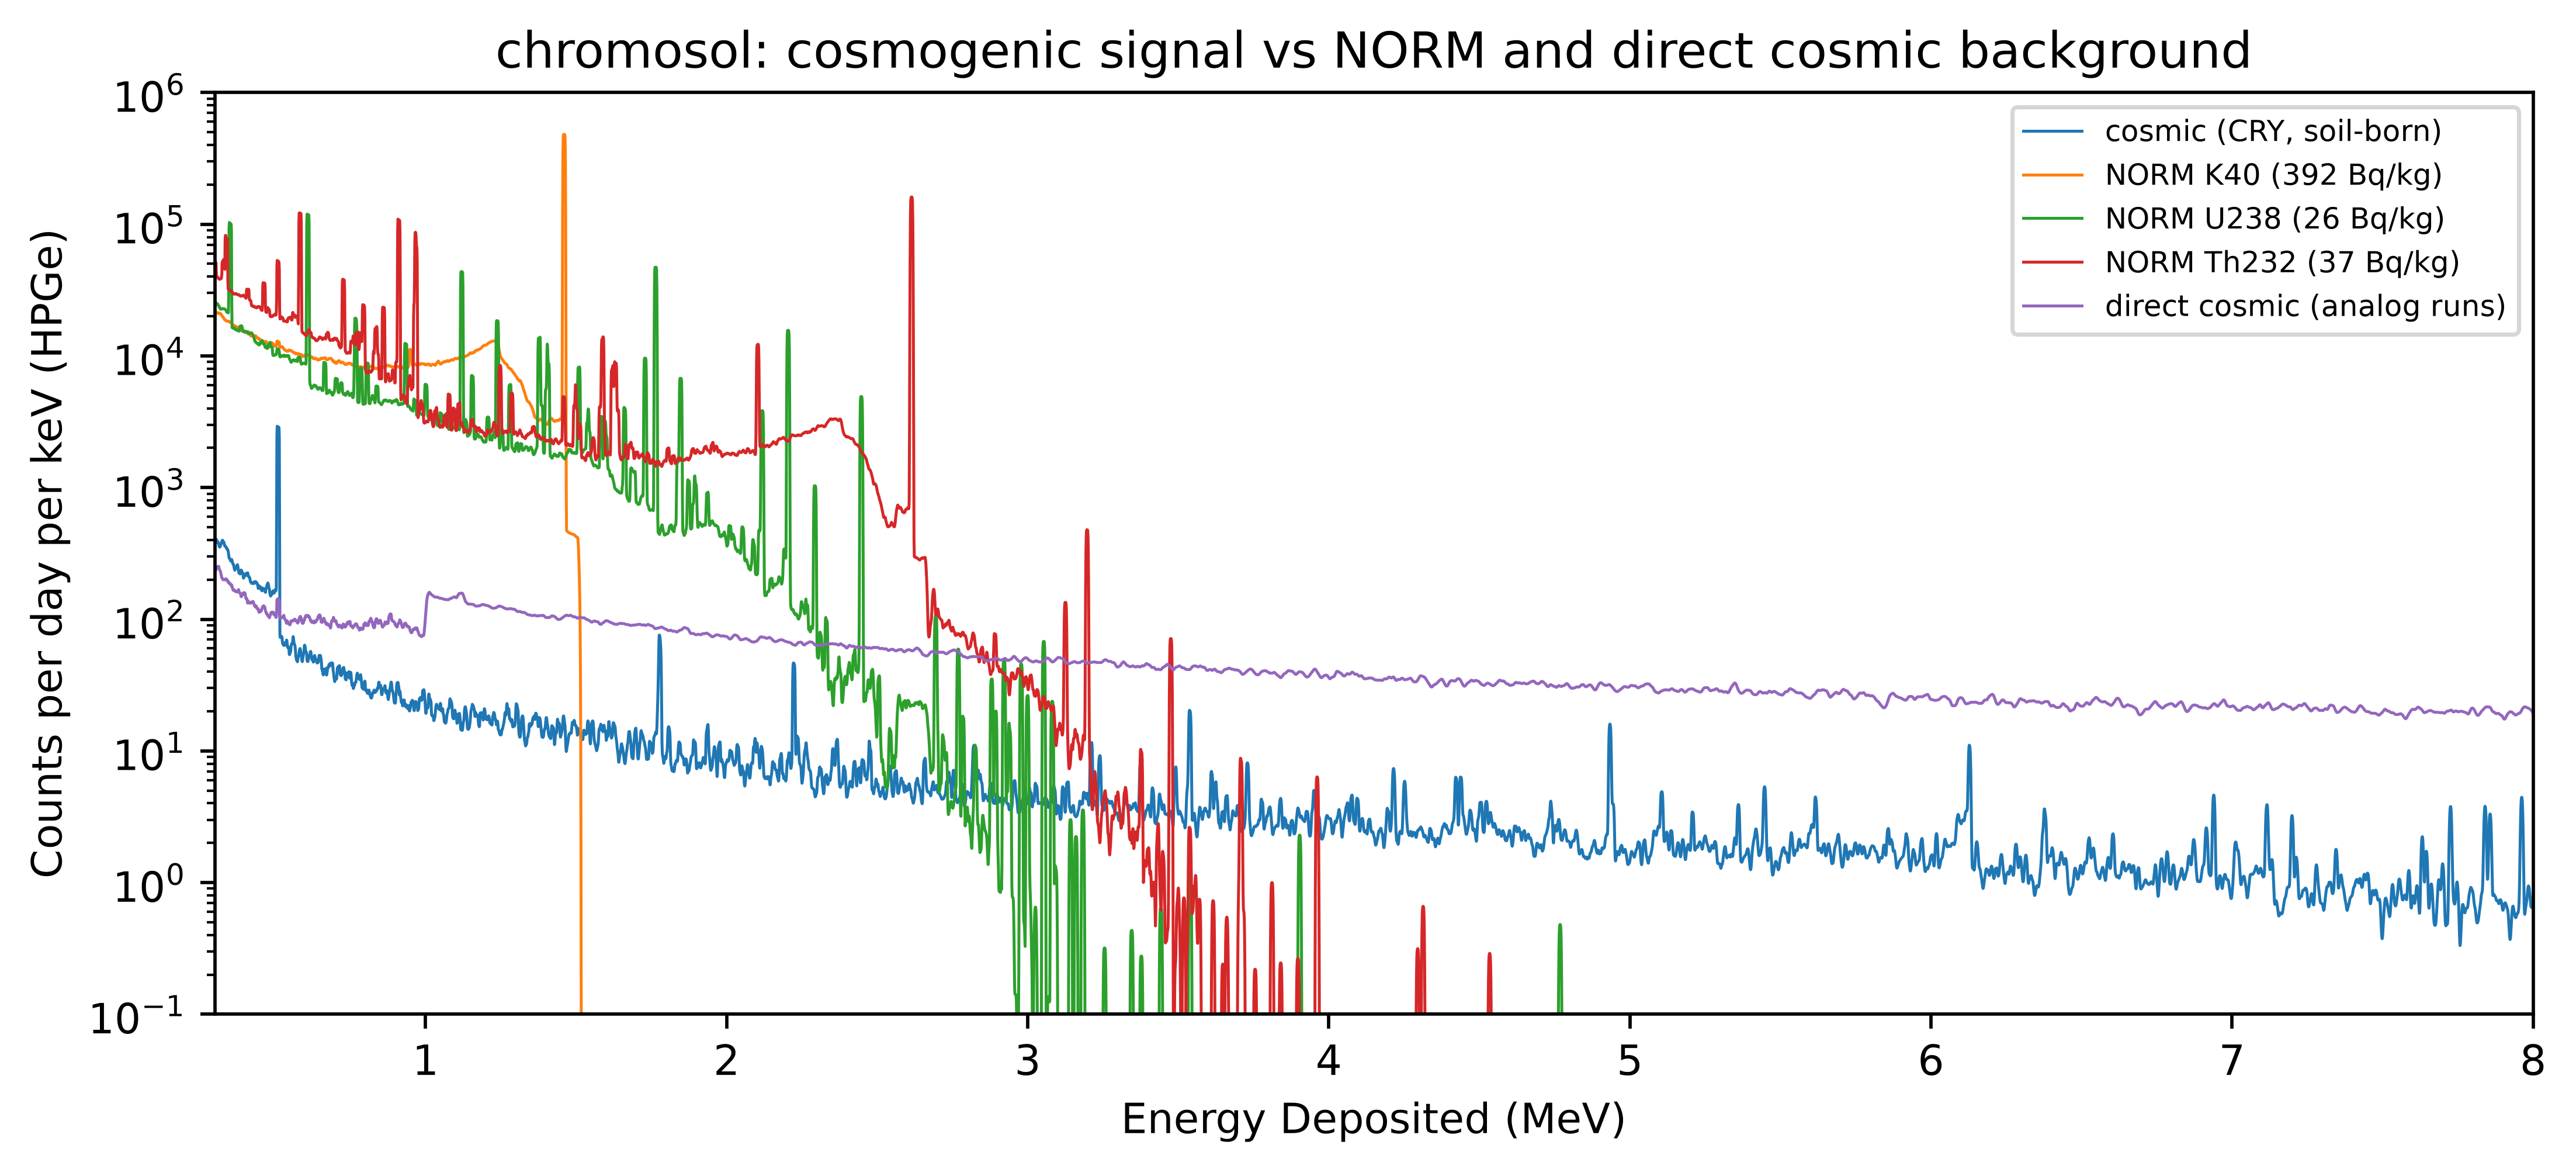

,net soil cosmic /day,NORM in window /day,direct cosmic in window /day,cosmic soil in window /day,signal / everything else in window
line,,,,,
2.223 H capture,340.579,15496.805,383.883,389.443,0.021
4.438 C (narrow),28.638,0.000,272.322,53.744,0.096
4.40-4.48 C (wide),68.868,0.000,2820.710,297.582,0.023
6.129 O inelastic,73.450,0.000,232.290,97.235,0.287
3.539 Si capture,141.818,35.162,290.952,171.335,0.399
0.511 annihilation,24765.192,469435.055,770.934,25346.883,0.053


In [16]:
acts = L.activities(ORDER)
parts = {"cosmic (CRY, soil-born)": L.cry(ORDER)}
for iso in L.ISOTOPES:
    parts[f"NORM {iso} ({acts[iso]:.0f} Bq/kg)"] = L.norm_pooled(ORDER, iso)[0] * acts[iso]
parts["direct cosmic (analog runs)"] = L.direct_background()[None, :]  # one row, no batch split
smeared = {k: L.smear(v, "HPGe").sum(0) * DAY for k, v in parts.items()}

fig, ax = plt.subplots(figsize=(10, 4))
for k, v in smeared.items():
    ax.semilogy(L.E_MEV, L.smooth(v[None, :], 9)[0], lw=0.7, label=k)
ax.set_xlim(0.3, 8)
ax.set_ylim(1e-1, 1e6)
ax.set_xlabel("Energy Deposited (MeV)")
ax.set_ylabel("Counts per day per keV (HPGe)")
ax.set_title(f"{ORDER}: cosmogenic signal vs NORM and direct cosmic background")
ax.legend(fontsize=7)
plt.show()

rows = []
for name in ["2.223 H capture", "4.438 C (narrow)", "4.40-4.48 C (wide)", "6.129 O inelastic", "3.539 Si capture", "0.511 annihilation"]:
    a = L.obs_weights(name, "HPGe")
    row = {"line": name, "net soil cosmic /day": smeared["cosmic (CRY, soil-born)"] @ a}
    row["NORM in window /day"] = sum(v[a > 0].sum() for k, v in smeared.items() if k.startswith("NORM"))
    row["direct cosmic in window /day"] = smeared["direct cosmic (analog runs)"][a > 0].sum()
    row["cosmic soil in window /day"] = smeared["cosmic (CRY, soil-born)"][a > 0].sum()
    rows.append(row)
t = pd.DataFrame(rows).set_index("line")
t["signal / everything else in window"] = t["net soil cosmic /day"] / (
    t["NORM in window /day"] + t["direct cosmic in window /day"] + t["cosmic soil in window /day"] - t["net soil cosmic /day"])
t.round(3)

## V4: SOC sensitivity in all five soil Orders

This applies Jay's `analyse_peak_trend` idea to every Order. It fits a straight line to the net line
counts (HPGe resolution, sideband-subtracted) over the five SOC levels. The 1-day SOC uncertainty is
sqrt(variance of the net count per day) / slope. The variance comes from all the counts in the peak
and sideband windows: soil cosmic only (as in Jay's analysis), then with the soil's NORM and the direct
cosmic background added. The 2.223 MeV slope without the capture correction shows how much the
correction matters. Where the fitted slope is not significant at 2σ, the σ_SOC columns are NaN: the
campaign's statistics do not resolve that line's SOC dependence. Such lines also give noisy, large
numbers in the confounder table below.

central SOC %  net /day (central)  \
line               Order                                           
2.223 H capture    calcarosol           0.58              403.98   
                   chromosol            0.91              340.58   
                   dermosol             1.48              443.84   
                   kandosol             0.48              353.18   
                   vertosol             0.63              522.99   
4.40-4.48 C (wide) calcarosol           0.58               80.99   
                   chromosol            0.91               68.87   
                   dermosol             1.48              109.28   
                   kandosol             0.48               52.56   
                   vertosol             0.63              110.26   
4.438 C (narrow)   calcarosol           0.58               32.88   
                   chromosol            0.91               28.64   
                   dermosol             1.48               40.59   
                   kandosol             0.48               31.43   
                   vertosol             0.63               58.39   

                              slope /day per % SOC  \
line               Order                             
2.223 H capture    calcarosol           33.5 ± 5.1   
                   chromosol            39.2 ± 3.5   
                   dermosol             34.8 ± 2.6   
                   kandosol             35.7 ± 7.0   
                   vertosol             38.1 ± 7.1   
4.40-4.48 C (wide) calcarosol           -0.1 ± 9.5   
                   chromosol            14.6 ± 8.1   
                   dermosol             -0.8 ± 4.0   
                   kandosol            39.7 ± 20.6   
                   vertosol            18.6 ± 10.5   
4.438 C (narrow)   calcarosol            6.9 ± 2.5   
                   chromosol             4.3 ± 1.7   
                   dermosol              1.9 ± 1.1   
                   kandosol              8.0 ± 4.5   
                   vertosol              2.7 ± 2.1   

                               σ_SOC 1 day, cosmic only (% SOC)  \
line               Order                                          
2.223 H capture    calcarosol                              0.68   
                   chromosol                               0.53   
                   dermosol                                0.66   
                   kandosol                                0.59   
                   vertosol                                0.65   
4.40-4.48 C (wide) calcarosol                               NaN   
                   chromosol                                NaN   
                   dermosol                                 NaN   
                   kandosol                                 NaN   
                   vertosol                                 NaN   
4.438 C (narrow)   calcarosol                              1.21   
                   chromosol                               2.02   
                   dermosol                                 NaN   
                   kandosol                                 NaN   
                   vertosol                                 NaN   

                               σ_SOC 1 day, + NORM + direct (% SOC)  \
line               Order                                              
2.223 H capture    calcarosol                                  5.10   
                   chromosol                                   4.60   
                   dermosol                                    5.38   
                   kandosol                                    4.91   
                   vertosol                                    4.47   
4.40-4.48 C (wide) calcarosol                                   NaN   
                   chromosol                                    NaN   
                   dermosol                                     NaN   
                   kandosol                                     NaN   
                   vertosol       

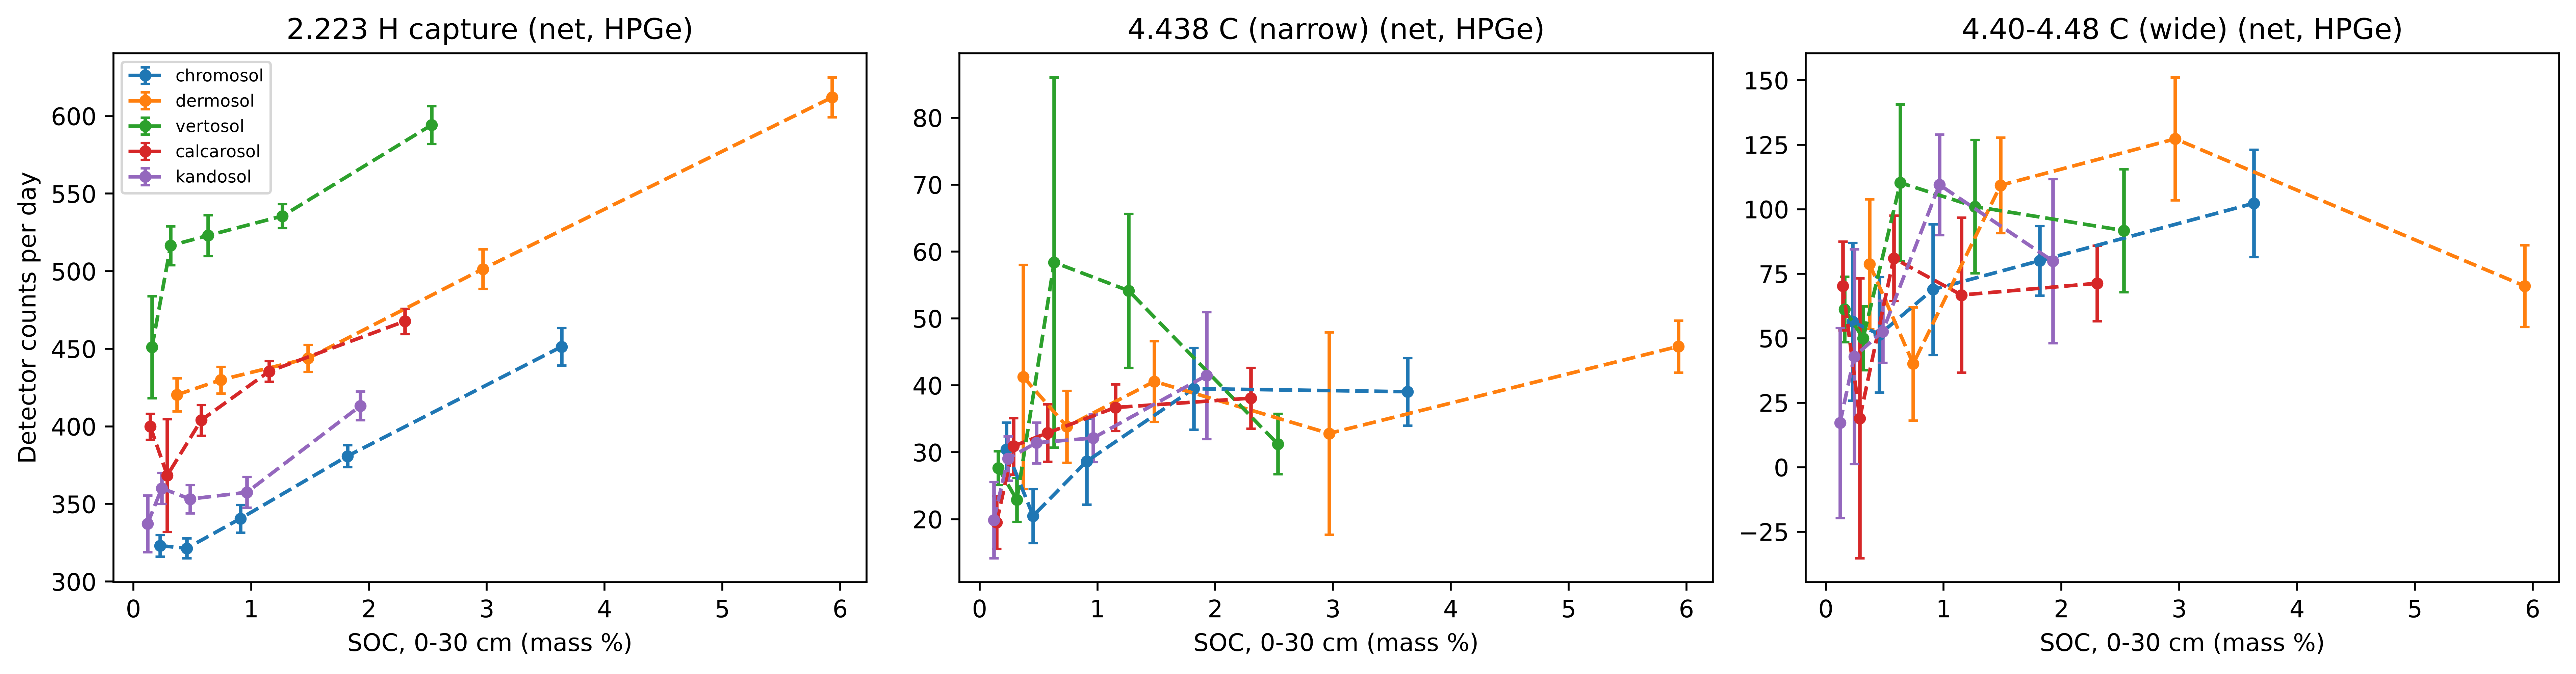

In [17]:
LINES = ["2.223 H capture", "4.438 C (narrow)", "4.40-4.48 C (wide)"]
direct = L.smear(L.direct_background()[None, :], "HPGe")[0] * DAY
rows, curves = [], {}
for o in L.ORDERS:
    rids = sorted((r for r in L.design_runs(o, "soc", extended=True) if not r.endswith("_rep")), key=soc_of)
    soc = np.array([soc_of(r) for r in rids])
    spec = {r: L.smear(L.cry(r), "HPGe") * DAY for r in rids}
    raw = {r: L.smear(L.cry(r, correct=False), "HPGe") * DAY for r in rids}
    norm = L.smear(L.norm_model(o), "HPGe").sum(0) * DAY
    for name in LINES:
        a = L.obs_weights(name, "HPGe")
        vals = np.array([spec[r].sum(0) @ a for r in rids])
        errs = np.array([np.sqrt(L.N_BATCH * (spec[r] @ a).var(ddof=1)) for r in rids])
        (m, c), cov = np.polyfit(soc, vals, 1, w=1 / errs, cov="unscaled")
        resolved = abs(m) > 2 * np.sqrt(cov[0, 0])  # slope significant at 2 sigma
        mu = spec[o].sum(0)
        var_cosmic = (a ** 2) @ mu
        var_field = (a ** 2) @ (mu + norm + direct)
        row = {"Order": o, "line": name, "central SOC %": soc_of(o), "net /day (central)": vals[rids.index(o)],
               "slope /day per % SOC": f"{m:.1f} ± {np.sqrt(cov[0, 0]):.1f}",
               "σ_SOC 1 day, cosmic only (% SOC)": np.sqrt(var_cosmic) / m if resolved else np.nan,
               "σ_SOC 1 day, + NORM + direct (% SOC)": np.sqrt(var_field) / m if resolved else np.nan,
               "σ_SOC 30 days, + NORM + direct (% SOC)": np.sqrt(var_field / 30) / m if resolved else np.nan}
        if name.startswith("2.223"):
            raw_vals = np.array([raw[r].sum(0) @ a for r in rids])
            row["slope without capture correction"] = np.polyfit(soc, raw_vals, 1)[0]
        rows.append(row)
        curves[(o, name)] = (soc, vals, errs)
sens = pd.DataFrame(rows).set_index(["line", "Order"]).sort_index()
display(sens.round(2))

fig, axs = plt.subplots(1, len(LINES), figsize=(15, 4))
for ax, name in zip(axs, LINES):
    for o in L.ORDERS:
        soc, vals, errs = curves[(o, name)]
        ax.errorbar(soc, vals, yerr=errs, fmt="o--", ms=4, capsize=2, label=o)
    ax.set_title(f"{name} (net, HPGe)")
    ax.set_xlabel("SOC, 0-30 cm (mass %)")
axs[0].set_ylabel("Detector counts per day")
axs[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

## V4: soil parameters that mimic SOC

Each one-at-a-time run changes one soil parameter about the central soil (water, bulk density, Gd, B,
Fe, carbonate, ...). Each change in the net line rate is expressed in % SOC that would produce the
same change, using the slopes above. Large numbers mean that parameter must be known (or measured)
to use the line for SOC.

In [18]:
slopes = {(o, n): np.polyfit(*curves[(o, n)][:2], 1)[0] for o in L.ORDERS for n in LINES}
suffixes = ["water_dry", "water_wet", "water_sat", "bd_minus10", "bd_plus10", "om_hrich", "structh_zero",
            "structh_high", "gd_p10", "gd_p90", "b5", "b60", "carb_add", "fe_x0.5", "fe_x2", "matrix_lo",
            "matrix_hi", "soc_top15_x2", "rep"]
rows = []
for o in L.ORDERS:
    central = {n: L.smear(L.cry(o), "HPGe").sum(0) * DAY @ L.obs_weights(n, "HPGe") for n in LINES}
    for s in suffixes:
        r = f"{o}_{s}" if not (o == "calcarosol" and s == "carb_add") else "calcarosol_carb_p90"
        if not (L.REDUCED / f"{r}.json").exists():
            continue
        spec = L.smear(L.cry(r), "HPGe").sum(0) * DAY
        for n in LINES:
            rows.append({"variant": s, "Order": o, "line": n,
                         "SOC-equivalent (% SOC)": (spec @ L.obs_weights(n, "HPGe") - central[n]) / slopes[(o, n)]})
conf = pd.DataFrame(rows).pivot_table(index="variant", columns=["line", "Order"], values="SOC-equivalent (% SOC)")
conf.reindex(suffixes).round(2)

line         2.223 H capture                                       \
Order             calcarosol chromosol dermosol kandosol vertosol   
variant                                                             
water_dry              -2.43     -3.69    -4.42    -4.01    -2.55   
water_wet               3.68      3.62     4.03     3.92     1.97   
water_sat               8.14      9.26     9.52     9.53     6.26   
bd_minus10              1.37      1.20     1.80     0.76     1.21   
bd_plus10              -0.78     -0.75    -0.31    -0.56    -1.29   
om_hrich                1.03      1.54     1.55     0.53     0.12   
structh_zero           -0.77     -0.92    -0.76    -1.21    -1.40   
structh_high            2.28      1.49     2.00     1.69     0.96   
gd_p10                  1.05      0.47     0.65    -0.08     0.08   
gd_p90                 -0.03     -0.67    -0.20    -0.65    -0.57   
b5                      0.76      0.58     1.02     0.39     0.31   
b60                    -0.85     -0.95    -0.90    -1.37    -1.52   
carb_add                1.05      0.25     0.53     0.55    -0.37   
fe_x0.5                 1.02      0.49     0.82     0.51     0.06   
fe_x2                   0.07      0.06    -0.40    -0.24    -0.99   
matrix_lo               0.98      1.47     1.30     0.20     0.44   
matrix_hi              -0.23     -0.04    -0.94    -0.64    -1.09   
soc_top15_x2            1.00      1.25     1.28     0.60     0.42   
rep                     0.47      0.10     0.82     0.55     0.25   

line         4.40-4.48 C (wide)                                       \
Order                calcarosol chromosol dermosol kandosol vertosol   
variant                                                                
water_dry                 -0.13      2.03   -25.19     1.41     0.30   
water_wet                 -4.26     -1.87   -25.20     1.58    -0.63   
water_sat                 -4.56      0.61   -34.23     0.66    -4.42   
bd_minus10                -1.52      0.07   -21.88     0.59    -4.10   
bd_plus10                -10.69     -2.51    -5.42     1.14    -3.33   
om_hrich                  -5.71     -3.72   -30.90     1.36    -3.89   
structh_zero              -2.21      0.96    -6.79    -0.64    -7.02   
structh_high              -2.90      1.18   -22.73    -0.60    -3.88   
gd_p10                     0.82      0.68   -14.54     0.04    -5.17   
gd_p90                    -2.10     -0.87   -19.30     0.07    -3.66   
b5                         0.25     -1.83   -13.63     0.25    -5.44   
b60                       -5.91      1.80   -38.24    -0.59    -6.00   
carb_add                   1.49     -0.53   -12.08     0.54    -2.00   
fe_x0.5                    1.33     -1.67   -37.22     1.50    -0.30   
fe_x2                      8.35      0.15    -8.84     0.32    -4.33   
matrix_lo                  3.99     -2.17   -20.66     1.02    -4.27   
matrix_hi                 -8.30      2.03   -27.31     1.46    -6.25   
soc_top15_x2               0.70      1.15   -16.63     0.50    -4.46   
rep                       -2.29     -1.55     4.31     1.71    -4.23   

line         4.438 C (narrow)                                       
Order              calcarosol chromosol dermosol kandosol vertosol  
variant                                                             
water_dry               -2.47     -1.10   -13.06     2.95   -16.79  
water_wet               -0.47      0.24   -12.74    -4.41   -22.98  
water_sat               -1.66      0.46   -14.49     1.00   -15.67  
bd_minus10              -1.88     -0.01    -5.46    -0.66   -18.37  
bd_plus10               -0.29      0.63   -12.68    -0.14   -19.18  
om_hrich                -0.59      0.45    -8.17     1.16   -22.02  
structh_zero            -0.93     -0.17   -17.39     0.49   -24.06  
structh_high            -0.77      0.13    -4.86    -0.38   -22.57  
gd_p10                  -0.06      1.14    -9.96    -0.59   -20.30  
gd_p90                  -0.77      1.09   -13.30    -0.19   -28.65  

## V4: are the batch errors right? Replicate runs

Each Order's central soil was run twice with independent seeds (`<order>_rep`). For 154 windows of
50 keV (0.3-8 MeV), (central − replicate) / combined batch error should be a unit Gaussian
(χ²/dof ≈ 1). v3's error bars were 1.5x too small.

In [19]:
edges = np.arange(300, 8001, 50)
rows = []
for o in L.ORDERS:
    a, b = L.rebin(L.cry(o), edges), L.rebin(L.cry(o + "_rep"), edges)  # [32][windows]
    sa, sb = np.sqrt(L.N_BATCH * a.var(0, ddof=1)), np.sqrt(L.N_BATCH * b.var(0, ddof=1))
    pull = (a.sum(0) - b.sum(0)) / np.hypot(sa, sb)
    rows.append({"Order": o, "windows": len(pull), "χ²/dof": (pull ** 2).mean(), "pull mean": pull.mean(),
                 "pull sd": pull.std(ddof=1)})
pd.DataFrame(rows).set_index("Order").round(2)

,windows,χ²/dof,pull mean,pull sd
Order,,,,
chromosol,154,1.00,0.17,0.99
dermosol,154,1.03,0.07,1.02
vertosol,154,1.15,0.02,1.08
calcarosol,154,0.89,0.04,0.95
kandosol,154,1.07,-0.10,1.03


## V4: real NGSA sites

The 25 population runs are real National Geochemical Survey sites (5 per Order) at their own measured
composition, so water, density and chemistry change together with SOC. The lines show each Order's
one-at-a-time SOC series for comparison.

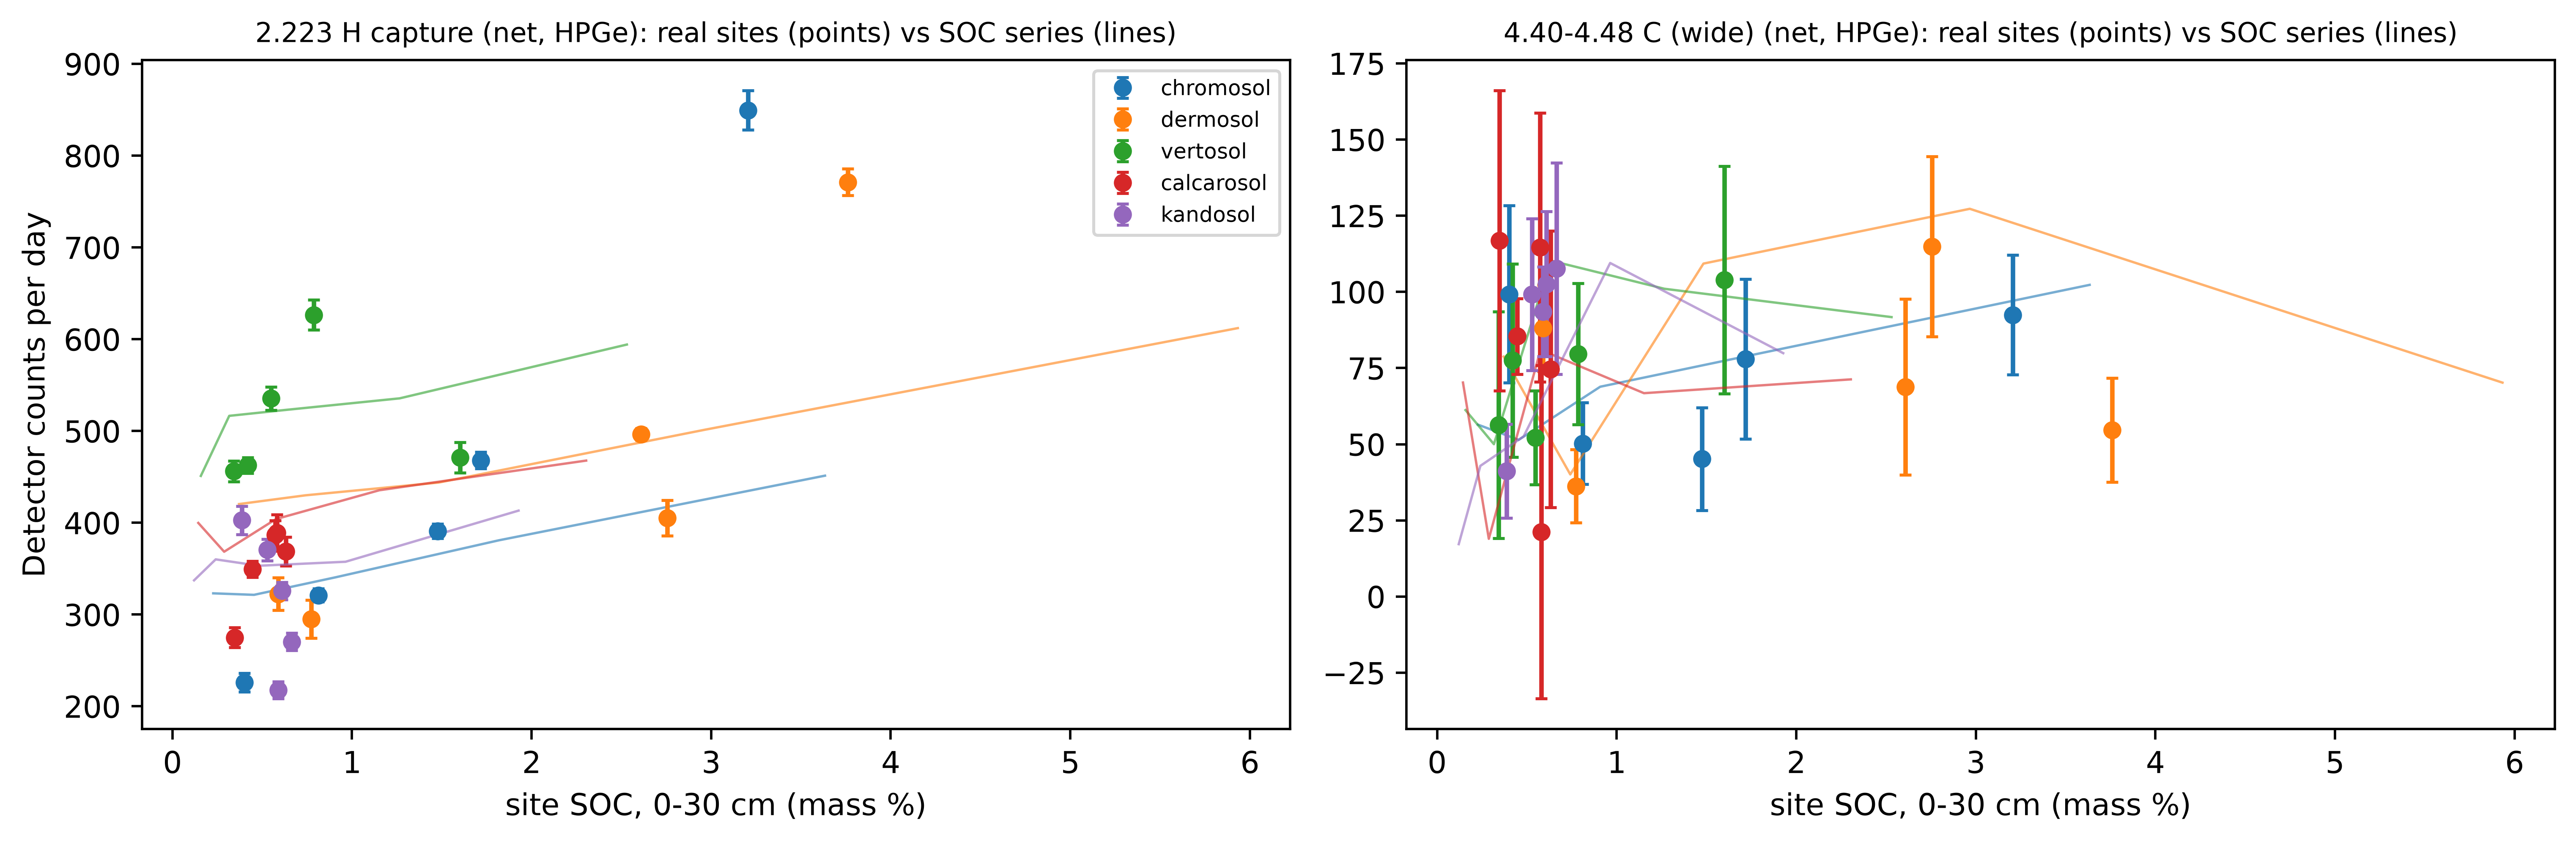

In [20]:
sites = [r for r in L.run_ids() if L.family(r) == "population"]
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axs, ["2.223 H capture", "4.40-4.48 C (wide)"]):
    a = L.obs_weights(name, "HPGe")
    for k, o in enumerate(L.ORDERS):
        soc, vals, errs = curves[(o, name)]
        ax.plot(soc, vals, "-", color=f"C{k}", lw=0.8, alpha=0.6)
        for r in [s for s in sites if L.order_of(s) == o]:
            spec = L.smear(L.cry(r), "HPGe") * DAY
            v = spec.sum(0) @ a
            ax.errorbar(soc_of(r), v, yerr=np.sqrt(L.N_BATCH * (spec @ a).var(ddof=1)), fmt="o", color=f"C{k}",
                        ms=5, capsize=2, label=o if r == [s for s in sites if L.order_of(s) == o][0] else None)
    ax.set_xlabel("site SOC, 0-30 cm (mass %)")
    ax.set_title(f"{name} (net, HPGe): real sites (points) vs SOC series (lines)", fontsize=9)
axs[0].set_ylabel("Detector counts per day")
axs[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

## V4: analog runs: pulse timing and the direct cosmic background

The analog runs simulate whole showers above Chromosol with the detector present (12 h of sky with a
5 m CRY box, 3 h with a 10 m box). Each pulse records the energy deposited by soil-born gammas and by
everything else, and the time since its shower started. Pulses whose energy came only from soil
gammas are what the production ⊗ transport runs simulate. All other pulses are the direct cosmic
background (muons, shower photons and electrons, ...), which a ground-level detector also records.

Neutron-capture gammas arrive long after the prompt shower, inelastic ones within ~1 µs. This replaces
Jay's "time of creation" plot (analyse-character), which needs per-gamma times. The 2.20-2.25 MeV
window holds the 2.223 MeV line plus prompt continuum, which is why part of it arrives within 1 µs.

Two caveats from the V4 report (§3.3) apply to the comparison table:
- An analog run only has showers inside its CRY box, so it misses soil gammas from neutrons born
  outside it. Production ⊗ transport is an infinite field by construction. The 5 m box reaches ~82%
  of it in 0.3-10 MeV and the 10 m box ~95%.
- CRY generates no photons or electrons below 1 MeV, so the direct background below 1 MeV is
  underestimated.

soil gamma, 2.20-2.25 MeV: median 136 µs; 26.2% within 1 µs
soil gamma, 4.40-4.48 MeV: median 0.1 µs; 67.7% within 1 µs
soil gamma, all: median 0.1 µs; 86.3% within 1 µs
direct cosmic background, all: median 0.1 µs; 95.0% within 1 µs


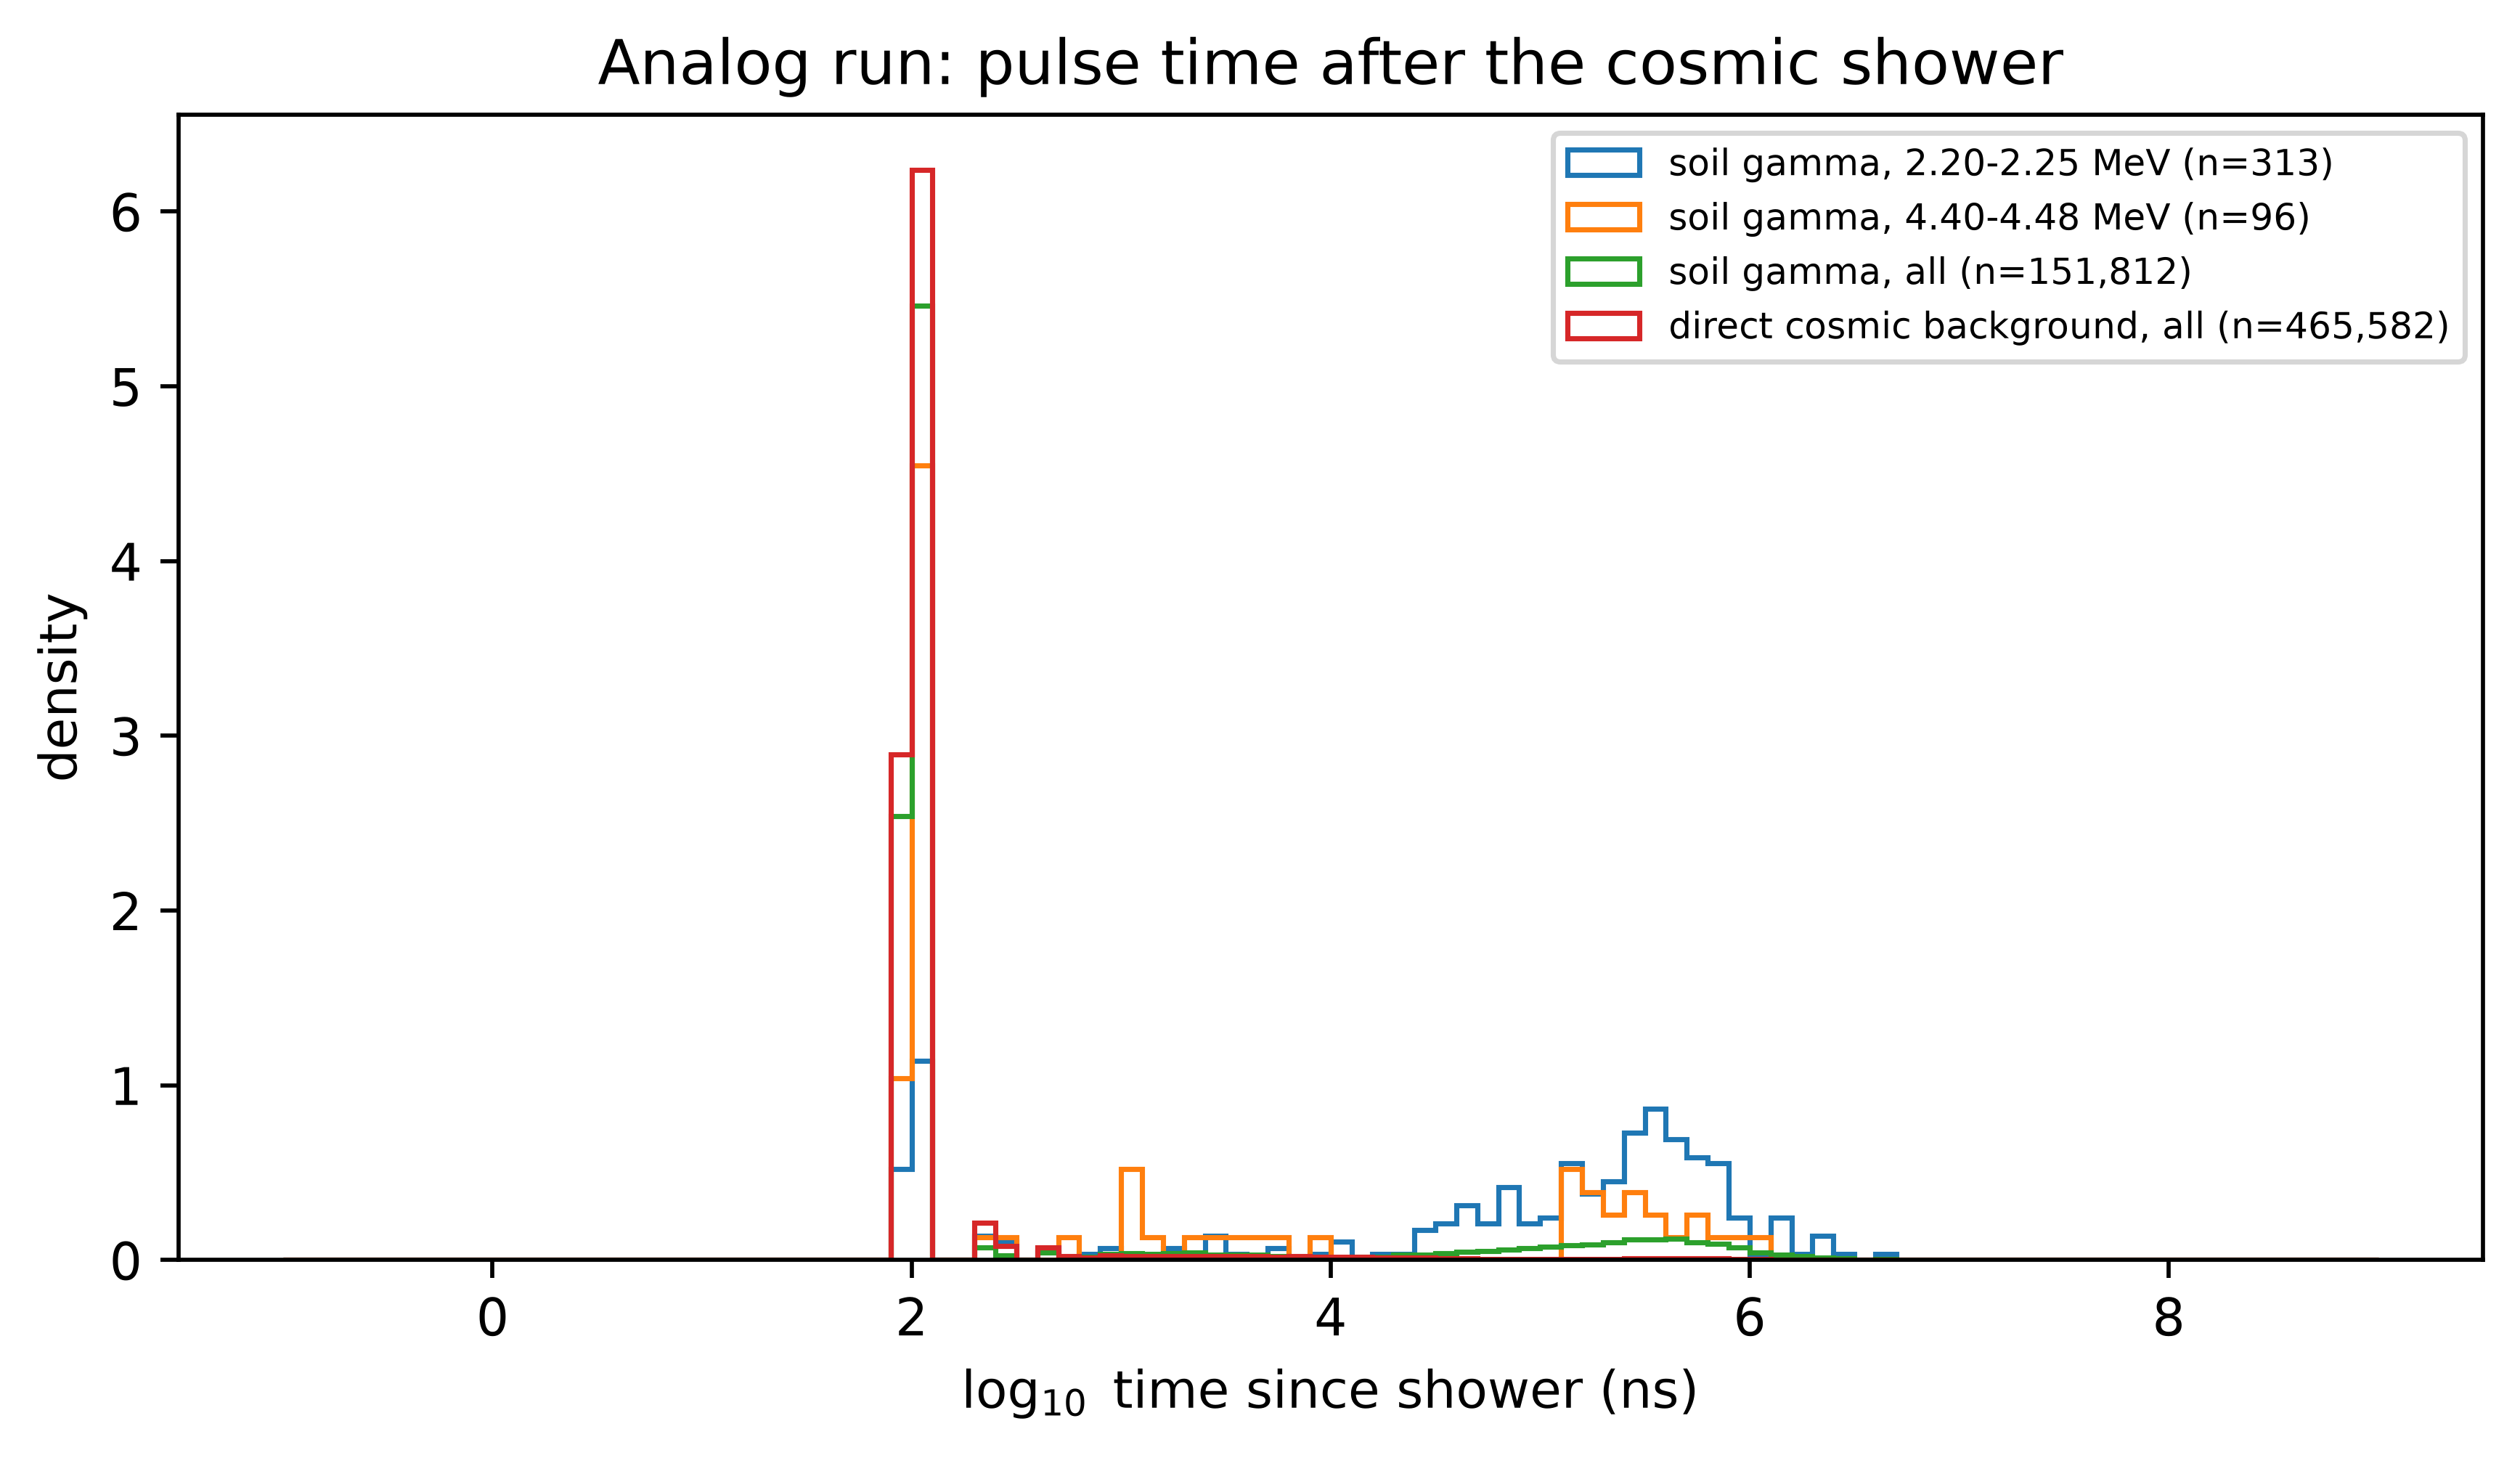

,analog soil-gamma /day,± (Poisson),production⊗transport /day,± (batch),direct cosmic /day,direct / soil
window,,,,,,
0.3-1 MeV,79155.95,397.88,93633.91,505.16,76475.95,0.82
1-3 MeV,15965.99,178.70,20917.12,262.61,163685.89,7.83
3-8 MeV,7763.99,124.61,10304.54,162.04,146213.90,14.19
2.223 ±3 keV,432.00,29.39,553.80,11.49,320.00,0.58
4.40-4.48 MeV,232.00,21.54,255.19,13.30,2692.00,10.55
total,370997.75,861.39,371025.79,1407.39,604325.59,1.63


In [21]:
aid = "analog_box5"
a = L.analog(aid)
p, tr = a["pulses"], a["p_trel"]
cls = L.analog_classes(aid)
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(-1, 9, 101)
for lab, m in [("soil gamma, 2.20-2.25 MeV", cls["soil_gamma"] & (p["edep_MeV"] > 2.20) & (p["edep_MeV"] < 2.25)),
               ("soil gamma, 4.40-4.48 MeV", cls["soil_gamma"] & (p["edep_MeV"] > 4.40) & (p["edep_MeV"] < 4.48)),
               ("soil gamma, all", cls["soil_gamma"]),
               ("direct cosmic background, all", cls["background"])]:
    t = tr[m & np.isfinite(tr) & (tr > 0)]
    ax.hist(np.log10(t), bins=bins, histtype="step", density=True, label=f"{lab} (n={len(t):,})")
    print(f"{lab}: median {np.median(t) / 1e3:.3g} µs; {np.mean(t < 1e3):.1%} within 1 µs")
ax.set_xlabel("$\\log_{10}$ time since shower (ns)")
ax.set_ylabel("density")
ax.set_title("Analog run: pulse time after the cosmic shower")
ax.legend(fontsize=7)
plt.show()

# analog soil-gamma pulses vs production (x) transport (same capture bug in both, so uncorrected)
pt = L.cry("chromosol", correct=False) * DAY
soil = L.analog_hist(aid, cls["soil_gamma"]) * DAY
soil_n = L.analog_hist(aid, cls["soil_gamma"]) * a["exposure_s"]
bg = L.analog_hist(aid, cls["background"]) * DAY
rows = []
for lab, (lo, hi) in {"0.3-1 MeV": (300, 1000), "1-3 MeV": (1000, 3000), "3-8 MeV": (3000, 8000),
                      "2.223 ±3 keV": (2220, 2226), "4.40-4.48 MeV": (4400, 4480), "total": (1, 12000)}.items():
    v, s = pt[:, lo:hi].sum(1).sum(), np.sqrt(L.N_BATCH * pt[:, lo:hi].sum(1).var(ddof=1))
    n = soil_n[lo:hi].sum()
    rows.append({"window": lab, "analog soil-gamma /day": soil[lo:hi].sum(), "± (Poisson)": soil[lo:hi].sum() / np.sqrt(max(n, 1)),
                 "production⊗transport /day": v, "± (batch)": s, "direct cosmic /day": bg[lo:hi].sum(),
                 "direct / soil": bg[lo:hi].sum() / v})
pd.DataFrame(rows).set_index("window").round(2)